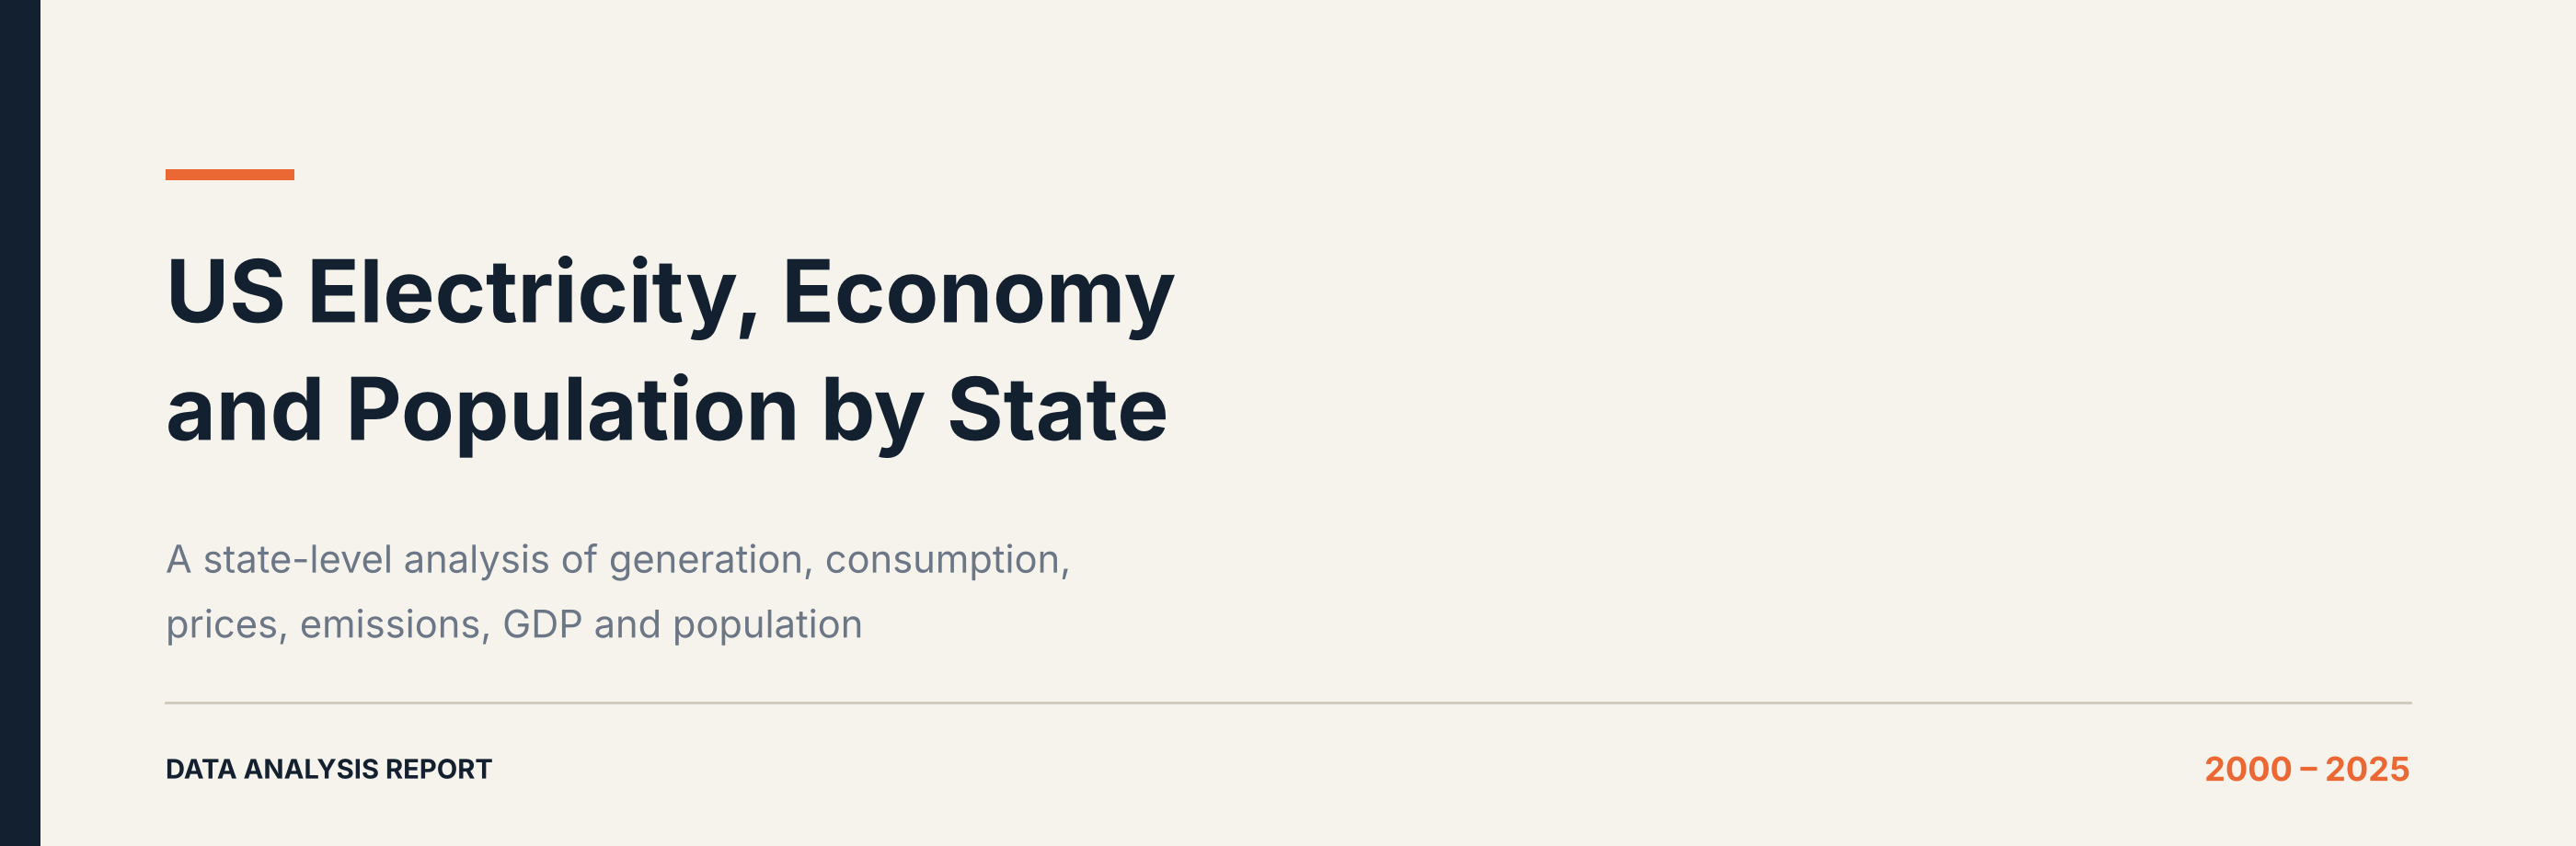

# US Electricity, Economy and Population by State (2000–2025)

**A state-level analysis of power generation, consumption, prices, emissions, GDP and population**

## Executive Summary

This report analyses how electricity generation, consumption, prices, emissions, the economy and population evolved across the US states between 2000 and 2025. Four state-level datasets were cleaned and joined into one state-year table, then analysed statistically, visualised, and examined with power-engineering methods.

**Headline findings**
- **The generation mix was transformed.** Coal fell from 51.1% of US generation in 2001 to 16.3% in 2025. Gas rose from 17.1% to 40.0%, and wind plus solar from about 0.2% to 18.9%.
- **Demand was flat, prices were not.** US consumption was about 3,421 TWh in 2000 and 3,480 TWh in 2025. The sales-weighted average price rose from 6.81 to 12.98 cents/kWh (+90%, nominal); residential prices doubled.
- **Cleaner electricity, not lower demand, cut emissions.** The Kaya/LMDI analysis in Section 7 separates the effects of population, economic growth, electricity use per dollar of GDP and carbon intensity of each kWh.
- **There is no single path away from coal.** Industrial states such as Ohio and Pennsylvania moved mostly to gas; Iowa and New Mexico moved to wind and solar.
- **One data issue needs attention.** 14 states show a sharp drop in reported retail sales from about 2010 (their consumption-to-generation ratio falls from about 99% to 52–67%, while the other 37 stay near 88%). This is most likely a reporting artefact, not a real fall in demand (see Section 9.2), so these states are flagged (`affected_break`) and analysed separately.

**What this means for decision-makers**
1. Do not use reported 2010–2025 sales of the 14 flagged states for trend or demand analysis; use the 37 unaffected states or generation data instead.
2. Prices in this report are nominal; deflate them before drawing conclusions about real cost changes.
3. State differences are large (mix, growth, price, intensity), so national averages should not be applied to individual states.

## Table of Contents

1. [Introduction](#1.-Introduction)
2. [Setup](#2.-Setup)
3. [Data Cleaning and Preparation](#3.-Data-Cleaning-and-Preparation)
4. [Generation and Consumption Statistics](#4.-Generation-and-Consumption-Statistics)
5. [Population and GDP Statistics](#5.-Population-and-GDP-Statistics)
6. [Visualisation and Insights](#6.-Visualisation-and-Insights)
7. [Power-System Engineering Analysis](#7.-Power-System-Engineering-Analysis)
8. [Key Insights and Conclusions](#8.-Key-Insights-and-Conclusions)
9. [Limitations and Recommended Extensions](#9.-Limitations-and-Recommended-Extensions)
10. [References](#10.-References)

## 1. Introduction

### 1.1 Context

The US power system changed fundamentally between 2000 and 2025: coal was displaced by natural gas and by wind and solar, electricity prices rose, and demand stayed almost flat while the economy and population grew. Looking at **state level** shows that there was no single path: each state followed its own resources, policies and industrial structure.

### 1.2 Purpose and scope

1. Build one clean, consistent **state-year dataset** (2000–2025) from four raw sources.
2. Describe **generation, consumption and prices** and detect data-quality problems.
3. Describe **economic size and population** and relate them to electricity use.
4. Visualise the main trends and state differences.
5. Apply **power-engineering methods** (power, capacity factor, diversity, emission factors, decomposition) to explain the observed changes.

### 1.3 Data sources

| Dataset (file) | Content | Unit | Period |
|---|---|---|---|
| Consumption (`consumption.csv`) | Retail sales, revenues and prices by sector (residential, commercial, industrial) | MWh, thousand USD, cents/kWh | 2000–2025 |
| GDP (`GDP__ALL_AREAS_1997_2025.csv`) | Current and real (chained 2017 USD) GDP and its components by state | million USD | 1997–2025 (2000–2025 used) |
| Generation and emissions (`release_us_subnational_generation_yearly.csv`) | Generation, share, emissions and emission intensity by state and source | TWh, MtCO2e, gCO2e/kWh | 2001–2025 |
| Population (`population_long.csv`) | Resident population by state | persons | 2000–2025 |

*The original publisher of each file is cited in Section 10.*

### 1.4 Approach

1. **Clean** each raw file (names, codes, duplicates, period, missing values, units).
2. **Merge** them once into `unified_dataset.csv` (one row per state and year).
3. **Describe** generation, consumption and prices; **flag** the 14 states with a reporting break.
4. **Describe** GDP and population and their relationship.
5. **Visualise** the results with a short comment under every figure.
6. **Analyse** the system with engineering equations (Section 7).

### 1.5 Scope notes

- The US total row is removed to avoid double counting.
- Sections 5 and 7 use the **50 states** (DC has no population record); Section 4 also includes DC (51 units).
- Puerto Rico appears only in the generation data and is excluded from comparisons.

### 1.6 Nomenclature and main equations

| Quantity | Symbol and equation | Unit |
|---|---|---|
| Unit conversion | $1\ \mathrm{TWh} = 10^{3}\ \mathrm{GWh} = 10^{6}\ \mathrm{MWh} = 10^{9}\ \mathrm{kWh}$ | – |
| Sales-weighted price | $\bar{p} = \dfrac{\sum_i R_i}{\sum_i S_i}\times 100$ ($R$ revenue in thousand USD, $S$ sales in MWh) | cents/kWh |
| Share of a source | $s_i = \dfrac{G_i}{\sum_j G_j}\times 100$ | % |
| Year-over-year growth | $g_t = \dfrac{X_t - X_{t-1}}{X_{t-1}}\times 100$ | % |
| Compound annual growth rate | $\mathrm{CAGR} = \left(\dfrac{X_T}{X_0}\right)^{1/(T-t_0)} - 1$ | %/year |
| GDP per capita | $y_{pc} = \dfrac{Y\times 10^{6}}{N}$ | USD/person |
| Electricity use per person | $e_{pc} = \dfrac{S\times 10^{9}}{N}$ | kWh/person |
| Consumption-to-generation ratio | $\eta_{sys} = \dfrac{S}{G}\times 100$ | % |
| Emission intensity | $I = \dfrac{E^{CO_2e}}{G}\times 1000$ | gCO2e/kWh |
| Average power | $P_{avg} = \dfrac{E\times 1000}{8760}$ | GW |
| Capacity factor | $CF = \dfrac{E}{P_{rated}\cdot T}$ | – |
| Herfindahl–Hirschman index | $HHI = \sum_i (100\,s_i)^2$ | 0–10 000 |
| Shannon entropy | $H = -\sum_i s_i \ln s_i$ | – |
| Kaya identity | $C = N\cdot\dfrac{Y}{N}\cdot\dfrac{G}{Y}\cdot\dfrac{C}{G}$ | MtCO2e |
| LMDI effect | $\Delta C_x = L(C_T,C_0)\ln\dfrac{x_T}{x_0}$, $\;L(a,b)=\dfrac{a-b}{\ln a-\ln b}$ | MtCO2e |
| Pearson correlation | $r = \dfrac{\sum (x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum (x_i-\bar x)^2\sum (y_i-\bar y)^2}}$ | – |
| IQR outlier fences | $[\,Q_1 - 1.5\,\mathrm{IQR},\; Q_3 + 1.5\,\mathrm{IQR}\,]$ | – |

Symbols: $S$ retail sales, $G$ generation, $R$ revenue, $Y$ GDP, $N$ population, $C$ emissions, $T$ period length in hours.

## 2. Setup

In [97]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from IPython.display import display

# Show wide tables in full instead of cutting columns
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)


def find(name):
    """Return the path of a data file, looking in the notebook folder and in ./data."""
    here = Path.cwd()
    for folder in (here, here / "data", here.parent / "data"):
        if (folder / name).exists():
            return folder / name
    raise FileNotFoundError(f"{name} not found in {here} or {here / 'data'} - put the data files next to the notebook")


print("Setup done.")
print("pandas", pd.__version__, "| numpy", np.__version__)

Setup done.
pandas 3.0.5 | numpy 2.2.0


## 3. Data Cleaning and Preparation

### 3.1 Settings

In [98]:
HERE = Path.cwd()
DATA = find("consumption.csv").parent   # folder that holds the raw files
OUT_DIR = HERE                          # clean files are saved next to the notebook
START, END = 2000, 2025                 # study period

STATES = {
    "Alabama": "AL", "Alaska": "AK", "Arizona": "AZ", "Arkansas": "AR", "California": "CA",
    "Colorado": "CO", "Connecticut": "CT", "Delaware": "DE", "District of Columbia": "DC",
    "Florida": "FL", "Georgia": "GA", "Hawaii": "HI", "Idaho": "ID", "Illinois": "IL",
    "Indiana": "IN", "Iowa": "IA", "Kansas": "KS", "Kentucky": "KY", "Louisiana": "LA",
    "Maine": "ME", "Maryland": "MD", "Massachusetts": "MA", "Michigan": "MI", "Minnesota": "MN",
    "Mississippi": "MS", "Missouri": "MO", "Montana": "MT", "Nebraska": "NE", "Nevada": "NV",
    "New Hampshire": "NH", "New Jersey": "NJ", "New Mexico": "NM", "New York": "NY",
    "North Carolina": "NC", "North Dakota": "ND", "Ohio": "OH", "Oklahoma": "OK", "Oregon": "OR",
    "Pennsylvania": "PA", "Rhode Island": "RI", "South Carolina": "SC", "South Dakota": "SD",
    "Tennessee": "TN", "Texas": "TX", "Utah": "UT", "Vermont": "VT", "Virginia": "VA",
    "Washington": "WA", "West Virginia": "WV", "Wisconsin": "WI", "Wyoming": "WY",
    "United States": "US",
}

print("Raw files are read from, and clean files saved to: the notebook folder")
print(f"Study period     : {START}-{END} ({END - START + 1} years)")
print(f"Areas in lookup  : {len(STATES)} (50 states + DC + US total)")

Raw files are read from, and clean files saved to: the notebook folder
Study period     : 2000-2025 (26 years)
Areas in lookup  : 52 (50 states + DC + US total)


### 3.2 Consumption data

#### 3.2.1 Load the raw file

In [99]:
cons = pd.read_csv(DATA / "consumption.csv", encoding="utf-8-sig", thousands=",")

print(f"Raw consumption file: {cons.shape[0]:,} rows x {cons.shape[1]} columns")
display(cons.head())

Raw consumption file: 1,872 rows x 18 columns


,Year,State,RES_Revenues(K),RES_Sales(MWAT/h),RES_Customers,RES_Price(Cents/kWh),COM_Revenues (K),COM_Sales(MWAT/h),COM_Customers,COM_Price(Cents/kWh),IND_Revenues(K),IND_Sales(MWAT/h),IND_Customers,IND_Price(Cents/kWh),TOTAL_Revenues(K),TOTAL_Sales(MWAT/h),TOTAL_Customers,TOTAL_Price(Cents/kWh)
0,2025,AK,532476,2039337,301478,26.11,580291,2596923,57465,22.35,281216,1415810,1218,19.86,1393983,6052070,360161,23.03
1,2025,AL,5358942,33304290,2422981,16.09,3334812,22839661,394133,14.60,2523270,32637830,7822,7.73,11217024,88781781,2824936,12.63
2,2025,AR,2476663,19246458,1491030,12.87,1285261,11947038,208609,10.76,1454809,21742903,37237,6.69,5216771,52936686,1736878,9.85
3,2025,AZ,6041478,39595028,3203578,15.26,4683890,37618662,352529,12.45,1195423,14858120,7447,8.05,11922005,92082779,3563556,12.95
4,2025,CA,16824419,59110353,8595350,28.46,15904022,67068380,1040736,23.71,5389284,27057704,118151,19.92,38190570,153580019,9754249,24.87


#### 3.2.2 Standardise the column names

In [100]:
old_names = list(cons.columns)
cons.columns = (cons.columns.str.strip()
                .str.replace(r"\s*\(.*?\)", "", regex=True)
                .str.lower())
cons = cons.rename(columns={"state": "state_code"})

names = pd.DataFrame({"before": old_names, "after": list(cons.columns)})
names["changed"] = names["before"] != names["after"]
print(f"{int(names['changed'].sum())} of {len(names)} column names changed:")
display(names)

18 of 18 column names changed:


,before,after,changed
0,Year,year,True
1,State,state_code,True
2,RES_Revenues(K),res_revenues,True
3,RES_Sales(MWAT/h),res_sales,True
4,RES_Customers,res_customers,True
5,RES_Price(Cents/kWh),res_price,True
6,COM_Revenues (K),com_revenues,True
7,COM_Sales(MWAT/h),com_sales,True
8,COM_Customers,com_customers,True
9,COM_Price(Cents/kWh),com_price,True


#### 3.2.3 Clean the state codes

In [101]:
codes_before = cons["state_code"].copy()
cons["state_code"] = cons["state_code"].str.strip().str.upper()

fixed = int((codes_before != cons["state_code"]).sum())
print(f"Rows whose state code needed fixing: {fixed}")
print(f"Distinct state codes now: {cons['state_code'].nunique()}")
print(", ".join(sorted(cons["state_code"].unique())))

Rows whose state code needed fixing: 0
Distinct state codes now: 52
AK, AL, AR, AZ, CA, CO, CT, DC, DE, FL, GA, HI, IA, ID, IL, IN, KS, KY, LA, MA, MD, ME, MI, MN, MO, MS, MT, NC, ND, NE, NH, NJ, NM, NV, NY, OH, OK, OR, PA, RI, SC, SD, TN, TX, US, UT, VA, VT, WA, WI, WV, WY


#### 3.2.4 Find and remove duplicate rows

In [102]:
key = ["year", "state_code"]

dup_before = int(cons.duplicated(subset=key).sum())
print(f"Duplicate rows BEFORE: {dup_before}")
if dup_before:
    display(cons[cons.duplicated(subset=key, keep=False)].sort_values(key)[key + ["total_sales"]].head(10))

rows_before = len(cons)
cons = cons.drop_duplicates(subset=key)
print(f"Rows removed         : {rows_before - len(cons)}")
print(f"Duplicate rows AFTER : {int(cons.duplicated(subset=key).sum())}")

Duplicate rows BEFORE: 0
Rows removed         : 0
Duplicate rows AFTER : 0


#### 3.2.5 Keep 2000–2025 only

In [103]:
per_year = cons.groupby("year").size()
print(f"BEFORE: years {per_year.index.min()}-{per_year.index.max()} "
      f"({per_year.size} years, {len(cons):,} rows)")

outside = per_year[(per_year.index < START) | (per_year.index > END)]
if len(outside):
    print("Rows removed, by year:")
    display(outside.rename("rows").to_frame().T)
else:
    print("No rows outside the study period.")

cons = cons[cons["year"].between(START, END)]
per_year = cons.groupby("year").size()
print(f"AFTER : years {per_year.index.min()}-{per_year.index.max()} "
      f"({per_year.size} years, {len(cons):,} rows)")

BEFORE: years 1990-2025 (36 years, 1,872 rows)
Rows removed, by year:


year,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999
rows,52,52,52,52,52,52,52,52,52,52


AFTER : years 2000-2025 (26 years, 1,352 rows)


#### 3.2.6 Check for missing values and zeros

In [104]:
missing = cons.isna().sum()
if missing.sum() == 0:
    print(f"Missing values: none, all {cons.shape[1]} columns are complete.")
else:
    print("Missing values per column:")
    display(missing[missing > 0].rename("missing").to_frame())

numeric = cons.select_dtypes("number").drop(columns=["year"])
zeros = (numeric == 0).sum()
zeros = zeros[zeros > 0]
if len(zeros):
    print("Zero values (columns that contain zeros):")
    display(zeros.rename("zero values").to_frame())
    zero_states = sorted(cons.loc[(numeric[zeros.index] == 0).any(axis=1), "state_code"].unique())
    print("States with zeros:", ", ".join(zero_states))
else:
    print("Zero values: none.")

Missing values: none, all 18 columns are complete.
Zero values (columns that contain zeros):


,zero values
ind_revenues,16
ind_sales,16
ind_customers,16
ind_price,16


States with zeros: DC


#### 3.2.7 Check that the US row equals the sum of the states

In [105]:
sectors = ["res_sales", "com_sales", "ind_sales", "total_sales"]
us_row = cons[cons["state_code"] == "US"].set_index("year")[sectors]
states_sum = cons[cons["state_code"] != "US"].groupby("year")[sectors].sum()
diff = us_row - states_sum

check = pd.DataFrame({"US row": us_row["total_sales"],
                      "Sum of states": states_sum["total_sales"],
                      "Difference": diff["total_sales"]})
display(check.iloc[::5])
print(f"Largest difference over all years and the 4 sales columns: {diff.abs().max().max():,.0f} MWh")

,US row,Sum of states,Difference
year,,,
2000,3421414266,3421414266,0
2005,3660968513,3660968513,0
2010,3375563915,3375563915,0
2015,3204048374,3204048374,0
2020,3158842284,3158842284,0
2025,3480233016,3480233016,0


Largest difference over all years and the 4 sales columns: 0 MWh


#### 3.2.8 Sort and confirm the final consumption table

In [106]:
cons = cons.sort_values(["year", "state_code"]).reset_index(drop=True)

areas, years = cons["state_code"].nunique(), cons["year"].nunique()
print(f"Clean consumption: {cons.shape[0]:,} rows x {cons.shape[1]} columns")
print(f"{areas} areas x {years} years = {areas * years:,} rows -> complete: {len(cons) == areas * years}")
print("(52 areas = 50 states + DC + the US total)")
display(cons.head())

Clean consumption: 1,352 rows x 18 columns
52 areas x 26 years = 1,352 rows -> complete: True
(52 areas = 50 states + DC + the US total)


,year,state_code,res_revenues,res_sales,res_customers,res_price,com_revenues,com_sales,com_customers,com_price,ind_revenues,ind_sales,ind_customers,ind_price,total_revenues,total_sales,total_customers,total_price
0,2000,AK,212474,1854968,230534,11.45,218572,2236477,38074,9.77,78418,1036627,854,7.56,535246,5309970,273530,10.08
1,2000,AL,2027802,28756115,1930037,7.05,1253946,19056898,313017,6.58,1357295,35034489,6252,3.87,4687257,83524220,2262753,5.61
2,2000,AR,1108516,14870777,1177901,7.45,518744,8746494,143544,5.93,725734,17268195,25597,4.20,2399365,41611188,1362838,5.77
3,2000,AZ,2096080,24843978,1959669,8.44,1572411,21410702,211921,7.34,631474,11975136,4760,5.27,4431208,61130045,2193562,7.25
4,2000,CA,8628982,79240641,11091616,10.89,9502420,92697488,1371137,10.25,4593965,64310844,42222,7.14,23105312,244057202,12537831,9.47


### 3.3 GDP data

#### 3.3.1 Load the raw file

In [107]:
gdp = pd.read_csv(DATA / "GDP__ALL_AREAS_1997_2025.csv", encoding="utf-8-sig")
year_cols_all = [c for c in gdp.columns if str(c).isdigit()]

print(f"Raw GDP file: {gdp.shape[0]:,} rows x {gdp.shape[1]} columns")
print(f"Year columns: {year_cols_all[0]} to {year_cols_all[-1]} ({len(year_cols_all)} columns)")
display(gdp.iloc[:5, :8])

Raw GDP file: 484 rows x 37 columns
Year columns: 1997 to 2025 (29 columns)


,GeoFIPS,GeoName,Region,TableName,LineCode,IndustryClassification,Description,Unit
0,"""00000""",United States,,SAGDP1,1.00,...,Real GDP (millions of chained 2017 dollars) 1/,Millions of chained 2017 dollars
1,"""00000""",United States,,SAGDP1,2.00,...,Chain-type quantity indexes for real GDP,Quantity index
2,"""00000""",United States,,SAGDP1,3.00,...,Current-dollar GDP (millions of current dollars),Millions of current dollars
3,"""00000""",United States,,SAGDP1,4.00,...,Compensation (millions of dollars),Millions of current dollars
4,"""00000""",United States,,SAGDP1,5.00,...,Gross operating surplus (millions of dollars),Millions of current dollars


#### 3.3.2 Remove footnote rows

In [108]:
notes = gdp[gdp["Description"].isna()]
print(f"Footnote rows found: {len(notes)}")
if len(notes):
    display(notes.dropna(axis=1, how="all").iloc[:, :2].head(10))

gdp = gdp.dropna(subset=["Description"])
print(f"Rows after removing them: {len(gdp):,}")

Footnote rows found: 4


,GeoFIPS
480,Note: See the included footnote file.
481,SAGDP1: State annual gross domestic product (G...
482,"Last updated: September 30, 2026-- revised sta..."
483,U.S. Bureau of Economic Analysis


Rows after removing them: 480


#### 3.3.3 Keep states, DC and the US total (drop regions)

In [109]:
gdp["GeoName"] = gdp["GeoName"].str.strip()
gdp["Description"] = gdp["Description"].str.strip()

areas_before = list(gdp["GeoName"].unique())
removed = [a for a in areas_before if a not in STATES]
gdp = gdp[gdp["GeoName"].isin(STATES)]

print(f"Areas BEFORE: {len(areas_before)}  |  AFTER: {gdp['GeoName'].nunique()}")
print("Removed:", ", ".join(removed) if removed else "none")
not_found = [a for a in STATES if a not in set(gdp["GeoName"])]
print("Expected areas that are missing:", ", ".join(not_found) if not_found else "none")

Areas BEFORE: 60  |  AFTER: 52
Removed: New England, Mideast, Great Lakes, Plains, Southeast, Southwest, Rocky Mountain, Far West
Expected areas that are missing: none


#### 3.3.4 Turn year columns into rows (wide to long)

In [110]:
year_cols = [str(y) for y in range(START, END + 1)]   # column names in the file are text
shape_wide = gdp.shape

long = gdp.melt(id_vars=["GeoName", "Description"], value_vars=year_cols,
                var_name="year", value_name="value")
long["year"] = long["year"].astype(int)

empty_before = int(long["value"].isna().sum())
long["value"] = pd.to_numeric(long["value"], errors="coerce")
not_numeric = int(long["value"].isna().sum()) - empty_before

print(f"Shape BEFORE (wide): {shape_wide}  ->  AFTER (long): {long.shape}")
print(f"Values that were not numbers and became NaN: {not_numeric}")
display(long.head())

Shape BEFORE (wide): (416, 37)  ->  AFTER (long): (10816, 4)
Values that were not numbers and became NaN: 0


,GeoName,Description,year,value
0,United States,Real GDP (millions of chained 2017 dollars) 1/,2000,"14,096,033.00"
1,United States,Chain-type quantity indexes for real GDP,2000,71.87
2,United States,Current-dollar GDP (millions of current dollars),2000,"10,250,952.00"
3,United States,Compensation (millions of dollars),2000,"5,854,629.00"
4,United States,Gross operating surplus (millions of dollars),2000,"3,733,603.00"


#### 3.3.5 Give each measure a short name

In [111]:
short = {
    "Real GDP (millions of chained 2017 dollars) 1/": "real_gdp_musd2017",
    "Chain-type quantity indexes for real GDP": "real_gdp_index",
    "Current-dollar GDP (millions of current dollars)": "gdp_current_musd",
    "Compensation (millions of dollars)": "compensation_musd",
    "Gross operating surplus (millions of dollars)": "gross_operating_surplus_musd",
    "Taxes on production and imports (TOPI) less subsides (millions of dollars)": "topi_less_subsidies_musd",
    "Taxes on production and imports (TOPI) (millions of dollars)": "topi_musd",
    "Subsidies (millions of dollars)": "subsidies_musd",
}

used = pd.Series(long["Description"].unique())
display(pd.DataFrame({"original name": used, "short name": used.map(short)}))

long["Description"] = long["Description"].map(short)
print("Rows left without a short name:", int(long["Description"].isna().sum()))

,original name,short name
0,Real GDP (millions of chained 2017 dollars) 1/,real_gdp_musd2017
1,Chain-type quantity indexes for real GDP,real_gdp_index
2,Current-dollar GDP (millions of current dollars),gdp_current_musd
3,Compensation (millions of dollars),compensation_musd
4,Gross operating surplus (millions of dollars),gross_operating_surplus_musd
5,Taxes on production and imports (TOPI) less su...,topi_less_subsidies_musd
6,Taxes on production and imports (TOPI) (millio...,topi_musd
7,Subsidies (millions of dollars),subsidies_musd


Rows left without a short name: 0


#### 3.3.6 Rebuild one row per state and year

In [112]:
gdp = long.pivot_table(index=["year", "GeoName"], columns="Description",
                       values="value", aggfunc="first").reset_index()
gdp.columns.name = None

print(f"Shape: {long.shape} (long)  ->  {gdp.shape} (one row per year and area)")
display(gdp.head())

Shape: (10816, 4) (long)  ->  (1352, 10) (one row per year and area)


,year,GeoName,compensation_musd,gdp_current_musd,gross_operating_surplus_musd,real_gdp_index,real_gdp_musd2017,subsidies_musd,topi_less_subsidies_musd,topi_musd
0,2000,Alabama,"69,762.30","120,522.60","43,268.20",77.88,"168,695.30",-371.80,"7,492.10","7,863.90"
1,2000,Alaska,"13,892.50","26,934.00","10,587.90",71.76,"38,428.10",-61.60,"2,453.60","2,515.20"
2,2000,Arizona,"91,213.70","165,735.60","63,405.70",67.47,"224,729.30",-433.80,"11,116.10","11,550.00"
3,2000,Arkansas,"38,764.90","69,176.30","26,482.90",77.10,"95,509.80",-979.80,"3,928.50","4,908.30"
4,2000,California,"768,407.20","1,354,791.30","507,233.20",65.11,"1,784,320.60","-4,473.90","79,150.90","83,624.80"


#### 3.3.7 Add the state code and drop measures not needed

In [113]:
gdp["state_code"] = gdp["GeoName"].map(STATES)
gdp = gdp.rename(columns={"GeoName": "state_name"})
gdp = gdp[["year", "state_code", "state_name"] + list(short.values())]

dropped = ["topi_musd", "subsidies_musd", "real_gdp_index"]
gdp = gdp.drop(columns=dropped).sort_values(["year", "state_code"]).reset_index(drop=True)

print("Columns dropped:", ", ".join(dropped))
print(f"Columns kept ({gdp.shape[1]}):", ", ".join(gdp.columns))
display(gdp.head())

Columns dropped: topi_musd, subsidies_musd, real_gdp_index
Columns kept (8): year, state_code, state_name, real_gdp_musd2017, gdp_current_musd, compensation_musd, gross_operating_surplus_musd, topi_less_subsidies_musd


,year,state_code,state_name,real_gdp_musd2017,gdp_current_musd,compensation_musd,gross_operating_surplus_musd,topi_less_subsidies_musd
0,2000,AK,Alaska,"38,428.10","26,934.00","13,892.50","10,587.90","2,453.60"
1,2000,AL,Alabama,"168,695.30","120,522.60","69,762.30","43,268.20","7,492.10"
2,2000,AR,Arkansas,"95,509.80","69,176.30","38,764.90","26,482.90","3,928.50"
3,2000,AZ,Arizona,"224,729.30","165,735.60","91,213.70","63,405.70","11,116.10"
4,2000,CA,California,"1,784,320.60","1,354,791.30","768,407.20","507,233.20","79,150.90"


#### 3.3.8 Check missing values and duplicates

In [114]:
missing = gdp.isna().sum()
if missing.sum() == 0:
    print(f"Missing values: none, all {gdp.shape[1]} columns are complete.")
else:
    print("Missing values per column:")
    display(missing[missing > 0].rename("missing").to_frame())

print("Duplicate rows (same year and state):", int(gdp.duplicated(subset=["year", "state_code"]).sum()))

areas, years = gdp["state_code"].nunique(), gdp["year"].nunique()
print(f"{areas} areas x {years} years = {areas * years:,} rows -> complete: {len(gdp) == areas * years}")
print(f"Clean GDP: {gdp.shape[0]:,} rows x {gdp.shape[1]} columns")

Missing values: none, all 8 columns are complete.
Duplicate rows (same year and state): 0
52 areas x 26 years = 1,352 rows -> complete: True
Clean GDP: 1,352 rows x 8 columns


### 3.4 Save the clean files

In [115]:
cons.to_csv(OUT_DIR / "consumption_clean.csv", index=False)
gdp.to_csv(OUT_DIR / "gdp_clean.csv", index=False)

summary = pd.DataFrame({
    "file":    ["consumption_clean.csv", "gdp_clean.csv"],
    "rows":    [len(cons), len(gdp)],
    "columns": [cons.shape[1], gdp.shape[1]],
    "areas":   [cons["state_code"].nunique(), gdp["state_code"].nunique()],
    "years":   [f"{cons['year'].min()}-{cons['year'].max()}", f"{gdp['year'].min()}-{gdp['year'].max()}"],
    "missing": [int(cons.isna().sum().sum()), int(gdp.isna().sum().sum())],
})
display(summary)

,file,rows,columns,areas,years,missing
0,consumption_clean.csv,1352,18,52,2000-2025,0
1,gdp_clean.csv,1352,8,52,2000-2025,0


### 3.5 Generation and emissions data

#### 3.5.1 Load the raw generation file

In [116]:
df = pd.read_csv(find("release_us_subnational_generation_yearly.csv"))

OUT = ""

#### 3.5.2 Structure of the raw table

In [117]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17377 entries, 0 to 17376
Data columns (total 17 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Area                                       17377 non-null  str    
 1   ISO 3 code                                 17377 non-null  str    
 2   State                                      17377 non-null  str    
 3   State code                                 17377 non-null  str    
 4   Year                                       17377 non-null  int64  
 5   Electricity source                         17377 non-null  str    
 6   Is aggregated source                       17377 non-null  bool   
 7   Generation (TWh)                           17377 non-null  float64
 8   Generation YoY change (TWh)                16621 non-null  float64
 9   Generation YoY change (%)                  16349 non-null  float64
 10  Share of generation (%)          

#### 3.5.3 Clean the table (strip text, drop duplicates, remove the US total and empty rows)

In [118]:
# 1) Cleaning
df.columns = df.columns.str.strip()

for c in ["State", "State code", "Electricity source"]:
    df[c] = df[c].astype(str).str.strip()

df = df.drop_duplicates()

df = df[df["State"] != "US (total)"]   # national total, not a state

df = df.dropna(subset=["Generation (TWh)", "Share of generation (%)"])  # empty rows (Puerto Rico, zero generation)

df["Year"] = df["Year"].astype(int)

df = df.sort_values(["Year", "State", "Electricity source"]).reset_index(drop=True)

#### 3.5.4 Structure after cleaning

In [119]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16991 entries, 0 to 16990
Data columns (total 17 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Area                                       16991 non-null  str    
 1   ISO 3 code                                 16991 non-null  str    
 2   State                                      16991 non-null  str    
 3   State code                                 16991 non-null  str    
 4   Year                                       16991 non-null  int64  
 5   Electricity source                         16991 non-null  str    
 6   Is aggregated source                       16991 non-null  bool   
 7   Generation (TWh)                           16991 non-null  float64
 8   Generation YoY change (TWh)                16263 non-null  float64
 9   Generation YoY change (%)                  15991 non-null  float64
 10  Share of generation (%)          

#### 3.5.5 Separate single sources from aggregated sources

In [120]:
base = ["Year", "State", "State code", "Electricity source"]

gen_cols = base + ["Generation (TWh)", "Share of generation (%)"]

em_cols = base + ["Emissions (MtCO2e)", "Share of emissions (%)", "Emissions intensity (gCO2e/kWh)"]

single = df[~df["Is aggregated source"]]

agg = df[df["Is aggregated source"]]

#### 3.5.6 Save the generation and emissions tables

In [121]:
single[gen_cols].to_csv(OUT + "us_state_generation_clean.csv", index=False)
agg[gen_cols].to_csv(OUT + "us_state_generation_aggregates.csv", index=False)
single[em_cols].to_csv(OUT + "us_state_emissions_clean.csv", index=False)

print(single[gen_cols].shape, agg[gen_cols].shape, single[em_cols].shape)
print(single[gen_cols].isna().sum().sum(), single[em_cols].isna().sum())

(9586, 6) (7405, 6) (9586, 7)
0 Year                                 0
State                                0
State code                           0
Electricity source                   0
Emissions (MtCO2e)                   0
Share of emissions (%)               0
Emissions intensity (gCO2e/kWh)    272
dtype: int64


### 3.6 Unified state-year dataset

In [122]:
# ============================================================
# Final master dataset: Consumption + GDP + Population
#                       + Generation + Emissions
# ============================================================

# 1) Read the cleaned files produced in the previous sections
cons_master = pd.read_csv("consumption_clean.csv")
gdp_master = pd.read_csv("gdp_clean.csv")
population_master = pd.read_csv(find("population_long.csv"))

generation_master = pd.read_csv("us_state_generation_clean.csv")
emissions_master = pd.read_csv("us_state_emissions_clean.csv")

# 2) Standardize the generation and emissions column names
generation_master = generation_master.rename(columns={
    "Year": "year",
    "State": "state_name_generation",
    "State code": "state_code",
    "Electricity source": "source",
    "Generation (TWh)": "generation_twh",
    "Share of generation (%)": "generation_share_pct"
})

emissions_master = emissions_master.rename(columns={
    "Year": "year",
    "State": "state_name_emissions",
    "State code": "state_code",
    "Electricity source": "source",
    "Emissions (MtCO2e)": "emissions_mtco2e",
    "Share of emissions (%)": "emissions_share_pct",
    "Emissions intensity (gCO2e/kWh)": "emissions_intensity_gco2e_kwh"
})

# 3) Standardize population columns
population_master = population_master.rename(
    columns={"state": "population_state_name"}
)

# Ensure there is only one population record per state and year
population_master = population_master.drop_duplicates(
    subset=["year", "state_code"]
)

# 4) Convert source-level generation/emissions rows into columns.
# This keeps one row per (year, state_code), without repeating
# consumption, GDP, and population for every electricity source.
def source_to_wide(frame, value_column, prefix):
    wide = frame.pivot_table(
        index=["year", "state_code"],
        columns="source",
        values=value_column,
        aggfunc="sum"
    )
    wide.columns = [f"{prefix}__{source}" for source in wide.columns]
    return wide.reset_index()

generation_wide = source_to_wide(
    generation_master, "generation_twh", "generation_twh"
)

generation_share_wide = source_to_wide(
    generation_master, "generation_share_pct", "generation_share_pct"
)

emissions_wide = source_to_wide(
    emissions_master, "emissions_mtco2e", "emissions_mtco2e"
)

emissions_share_wide = source_to_wide(
    emissions_master, "emissions_share_pct", "emissions_share_pct"
)

emissions_intensity_wide = source_to_wide(
    emissions_master, "emissions_intensity_gco2e_kwh",
    "emissions_intensity_gco2e_kwh"
)

# 5) Start with consumption and GDP, then add population and energy data.
# This is the ONLY master merge in the notebook.
unified_data = cons_master.merge(
    gdp_master,
    on=["year", "state_code"],
    how="inner"
)

unified_data = unified_data.merge(
    population_master,
    on=["year", "state_code"],
    how="left"
)

for source_table in [
    generation_wide,
    generation_share_wide,
    emissions_wide,
    emissions_share_wide,
    emissions_intensity_wide
]:
    unified_data = unified_data.merge(
        source_table,
        on=["year", "state_code"],
        how="left"
    )

# 6) Calculate GDP per capita once, in the unified dataset
unified_data["gdp_per_capita"] = (
    unified_data["gdp_current_musd"] * 1_000_000
    / unified_data["population"]
)

# Keep the dataset ordered and verify its grain
unified_data = unified_data.sort_values(
    ["year", "state_code"]
).reset_index(drop=True)

print("Unified dataset shape:", unified_data.shape)
print("Unique state-year rows:",
      unified_data[["year", "state_code"]].drop_duplicates().shape[0])
duplicate_state_years = unified_data.duplicated(["year", "state_code"]).sum()
print("Duplicate state-year rows:", duplicate_state_years)
print("Missing population:", unified_data["population"].isna().sum())

if duplicate_state_years:
    raise ValueError(
        "The unified dataset contains duplicate (year, state_code) rows. "
        "Check the source files before continuing."
    )

# 7) Save the single unified dataset
unified_data.to_csv("unified_dataset.csv", index=False)
print("Saved: unified_dataset.csv")

Unified dataset shape: (1352, 72)
Unique state-year rows: 1352
Duplicate state-year rows: 0
Missing population: 52
Saved: unified_dataset.csv


## 4. Generation and Consumption Statistics

### 4.1 Load the unified dataset

In [123]:
# Read the unified dataset

BREAK_RATIO   = 0.7
YOY_JUMP      = 0.4
MIN_TWH       = 20
PRE_BREAK_RATIO = 0.91
pd.reset_option("display.float_format")

# Read one dataset only
master = pd.read_csv("unified_dataset.csv")
cons = master.copy()

# Rebuild the source-level generation and emissions tables in memory.
# No additional files are read and no source datasets are merged here.
id_cols = ["year", "state_name", "state_code"]

def source_columns_to_long(frame, value_prefix, value_name,
                           extra_prefixes=None, extra_names=None):
    extra_prefixes = extra_prefixes or []
    extra_names = extra_names or []
    value_columns = [c for c in frame.columns if c.startswith(value_prefix)]
    parts = []

    for value_col in value_columns:
        source = value_col[len(value_prefix):]
        selected = id_cols + [value_col]
        rename_map = {value_col: value_name}

        for extra_prefix, extra_name in zip(extra_prefixes, extra_names):
            extra_col = extra_prefix + source
            if extra_col in frame.columns:
                selected.append(extra_col)
                rename_map[extra_col] = extra_name

        part = frame[selected].rename(columns=rename_map).copy()
        part["source"] = source
        parts.append(part)

    if not parts:
        return pd.DataFrame(columns=id_cols + ["source", value_name] + extra_names)

    return pd.concat(parts, ignore_index=True).dropna(subset=[value_name])

gen = source_columns_to_long(
    master,
    "generation_twh__",
    "generation_twh",
    extra_prefixes=["generation_share_pct__"],
    extra_names=["gen_share_pct"]
)

emis = source_columns_to_long(
    master,
    "emissions_mtco2e__",
    "emissions_mtco2e",
    extra_prefixes=[
        "emissions_share_pct__",
        "emissions_intensity_gco2e_kwh__"
    ],
    extra_names=["emis_share_pct", "emis_intensity_g_kwh"]
)

# Quick check of the unified dataset and reconstructed source-level tables
for name, frame in {"master": master, "consumption": cons,
                    "generation": gen, "emissions": emis}.items():
    print(name, frame.shape,
          "| missing:", int(frame.isna().sum().sum()),
          "| years:", frame["year"].min(), "-", frame["year"].max())

# Compare national consumption totals with the sum of state records,
# then remove the national total row from state-level analysis.
us = cons[cons["state_code"] == "US"].set_index("year")["total_sales"]
st = cons[cons["state_code"] != "US"].groupby("year")["total_sales"].sum()
print("max diff US vs sum of states:", (us - st).abs().max())

cons = cons[cons["state_code"] != "US"].copy()
print("cons after removing US:", cons.shape)

# The generation/emissions columns are already standardized in master.

master (1352, 72) | missing: 13381 | years: 2000 - 2025
consumption (1352, 72) | missing: 13381 | years: 2000 - 2025
generation (9523, 6) | missing: 0 | years: 2001 - 2025
emissions (9523, 7) | missing: 0 | years: 2001 - 2025
max diff US vs sum of states: 0
cons after removing US: (1326, 72)


### 4.2 Unit conversion (MWh to TWh)

In [124]:
# Convert units from megawatt-hours (MWh) to terawatt-hours (TWh) to match the generation dataset later.
for s in ["res", "com", "ind", "total"]:
    cons[f"{s}_sales_twh"] = cons[f"{s}_sales"] / 1e6

sales_cols = ["res_sales_twh", "com_sales_twh", "ind_sales_twh", "total_sales_twh"]
price_cols = ["res_price", "com_price", "ind_price", "total_price"]

### 4.3 Descriptive statistics

In [125]:
# Descriptive statistics
print(cons[sales_cols].describe().round(2))
print(cons[price_cols].describe().round(2))

       res_sales_twh  com_sales_twh  ind_sales_twh  total_sales_twh
count        1326.00        1326.00        1326.00          1326.00
mean           26.12          22.46          17.44            66.33
std            27.46          25.70          19.59            68.97
min             0.08           0.04           0.00             0.15
25%             6.84           6.42           3.73            20.65
50%            19.73          15.01          12.78            48.74
75%            33.90          27.82          24.20            86.85
max           170.60         174.68         188.11           533.26
       res_price  com_price  ind_price  total_price
count    1326.00    1326.00    1326.00      1326.00
mean       12.31      10.49       7.60        10.53
std         4.80       4.26       4.03         4.59
min         5.13       4.24       0.00         4.17
25%         9.14       7.79       5.37         7.63
50%        11.44       9.60       6.61         9.41
75%        13.80      11

### 4.4 Mean, median and skewness

In [126]:
# Compare the mean and median, and calculate the skewness coefficient
print("median:", cons[sales_cols].median().round(2).to_dict())
print("skew  :", cons[sales_cols].skew().round(2).to_dict())

median: {'res_sales_twh': 19.73, 'com_sales_twh': 15.01, 'ind_sales_twh': 12.78, 'total_sales_twh': 48.74}
skew  : {'res_sales_twh': 2.44, 'com_sales_twh': 2.59, 'ind_sales_twh': 3.29, 'total_sales_twh': 2.69}


### 4.5 Sector shares of consumption

In [127]:
# Each sector's share of total electricity consumption (%)
tot = cons[sales_cols].sum()
print((tot / tot["total_sales_twh"] * 100).round(1).to_dict())

{'res_sales_twh': 39.4, 'com_sales_twh': 33.9, 'ind_sales_twh': 26.3, 'total_sales_twh': 100.0}


### 4.6 Highest and lowest state-year values

In [128]:
# Identify the state and year with the highest and lowest values
print(cons.loc[cons["total_sales_twh"].idxmax(), ["year", "state_code", "total_sales_twh"]])
print(cons.loc[cons["total_sales_twh"].idxmin(), ["year", "state_code", "total_sales_twh"]])

year                     2025
state_code                 TX
total_sales_twh    533.260493
Name: 1343, dtype: object
year                   2010
state_code               ME
total_sales_twh    0.151588
Name: 541, dtype: object


### 4.7 Maine's series and detection of sudden jumps

In [129]:
# Display Maine's data across all years
me = cons[cons["state_code"] == "ME"][["year", "res_sales_twh", "com_sales_twh",
                                       "ind_sales_twh", "total_sales_twh"]]
print(me.round(2).to_string(index=False))

# Detect sudden increases and decreases in each state
cons = cons.sort_values(["state_code", "year"])
cons["total_yoy"] = cons.groupby("state_code")["total_sales_twh"].pct_change()

print(cons[cons["total_yoy"].abs() > YOY_JUMP]
      [["year", "state_code", "total_sales_twh", "total_yoy"]].round(2))

 year  res_sales_twh  com_sales_twh  ind_sales_twh  total_sales_twh
 2000           3.74           3.71           4.55            12.16
 2001           3.90           3.78           4.41            12.15
 2002           4.04           3.79           3.55            11.44
 2003           4.22           3.96           3.79            11.97
 2004           4.33           4.33           3.71            12.37
 2005           4.50           4.16           3.70            12.36
 2006           4.35           4.13           3.80            12.28
 2007           4.41           4.20           3.25            11.86
 2008           4.35           4.15           3.17            11.67
 2009           4.36           4.07           2.85            11.28
 2010           0.08           0.04           0.03             0.15
 2011           0.08           0.05           0.03             0.16
 2012           0.08           0.04           0.03             0.16
 2013           0.08           0.05           0.

### 4.8 National consumption versus generation

In [130]:
# Annual US totals: compare electricity consumption with generation
nat = cons.groupby("year")["total_sales_twh"].sum().to_frame("cons_twh")
nat["gen_twh"] = gen[gen["state_code"] != "PR"].groupby("year")["generation_twh"].sum()
nat["cons_to_gen_pct"] = nat["cons_twh"] / nat["gen_twh"] * 100
print(nat.round(1).to_string())

      cons_twh  gen_twh  cons_to_gen_pct
year                                    
2000    3421.4      NaN              NaN
2001    3394.5   3727.0             91.1
2002    3465.5   3843.7             90.2
2003    3493.7   3868.9             90.3
2004    3547.5   3952.0             89.8
2005    3661.0   4035.0             90.7
2006    3669.9   4046.9             90.7
2007    3764.6   4142.6             90.9
2008    3734.0   4107.5             90.9
2009    3596.8   3939.8             91.3
2010    3375.6   4113.9             82.1
2011    3282.9   4088.9             80.3
2012    3180.4   4040.7             78.7
2013    3165.7   4055.6             78.1
2014    3201.3   4096.0             78.2
2015    3204.0   4084.0             78.5
2016    3202.4   4087.5             78.3
2017    3163.6   4052.3             78.1
2018    3275.1   4201.6             77.9
2019    3227.7   4158.4             77.6
2020    3158.8   4043.2             78.1
2021    3230.3   4153.6             77.8
2022    3362.1  

### 4.9 Locating the 2010 reporting break

In [131]:
# Compare each state's 2025 value with its 2009 value
p = cons.pivot(index="state_code", columns="year", values="total_sales_twh")
ratio = (p[2025] / p[2009]).sort_values()
print(ratio.round(2).head(16).to_string())
print(f"states below {BREAK_RATIO}:", int((ratio < BREAK_RATIO).sum()))
print("national 2025/2009:", round(p[2025].sum() / p[2009].sum(), 2))

# Do the 14 states explain the national gap?
affected = ratio[ratio < BREAK_RATIO].index.tolist()

lost = (p.loc[affected, 2009] - p.loc[affected, 2025]).sort_values(ascending=False)
print("\n", lost.round(1).to_string())
print("total lost TWh (14 states):", round(lost.sum(), 1))

gen_2025 = nat.loc[2025, "gen_twh"]
expected = gen_2025 * PRE_BREAK_RATIO
actual = nat.loc[2025, "cons_twh"]
print("national gap TWh:", round(expected - actual, 1))

state_code
OH    0.26
MA    0.27
DC    0.28
NH    0.38
PA    0.38
IL    0.42
RI    0.44
CT    0.50
MD    0.55
ME    0.58
NY    0.58
CA    0.59
NJ    0.61
DE    0.68
KY    0.86
MT    0.88
states below 0.7: 14
national 2025/2009: 0.97

 state_code
OH    107.5
CA    106.0
PA     88.5
IL     79.4
NY     58.5
MA     39.9
NJ     29.3
MD     28.1
CT     15.0
DC      8.2
NH      6.7
ME      4.7
RI      4.3
DE      3.6
total lost TWh (14 states): 579.6
national gap TWh: 630.0


### 4.10 Consumption-to-generation ratio: affected versus unaffected states

In [132]:
# Generation by state and year (excluding Puerto Rico)
gen_state = (gen[gen["state_code"] != "PR"]
             .groupby(["year", "state_code"])["generation_twh"].sum()
             .unstack())

# States included in both datasets
common = [s for s in p.index if s in gen_state.columns]
unaff = [s for s in common if s not in affected]
aff   = [s for s in common if s in affected]
print("unaffected:", len(unaff), "| affected:", len(aff))

# Consumption-to-generation ratio for each group
r_un  = p.loc[unaff].sum() / gen_state[unaff].sum(axis=1) * 100
r_aff = p.loc[aff].sum()   / gen_state[aff].sum(axis=1) * 100

out = pd.DataFrame({"unaffected_pct": r_un, "affected_pct": r_aff}).loc[2005:2015]
print(out.round(1).to_string())

unaffected: 37 | affected: 14
      unaffected_pct  affected_pct
year                              
2005            87.3          99.1
2006            88.1          97.2
2007            87.8          98.4
2008            87.6          99.2
2009            88.2          99.2
2010            87.8          67.2
2011            87.9          60.4
2012            87.4          55.9
2013            88.0          52.0
2014            88.1          51.7
2015            87.9          52.8


### 4.11 Flagging the affected states

In [133]:
# Flag column: whether the state is among the 14 affected states
cons["affected_break"] = cons["state_code"].isin(affected)

# Period column: before and after the reporting break
cons["period"] = cons["year"].apply(lambda y: "2000-2009" if y <= 2009 else "2010-2025")

# Verify that the counts are correct
print(cons.groupby("affected_break")["state_code"].nunique())
print(cons.groupby(["affected_break", "period"]).size())
print(sorted(affected))

# Save a new copy without overwriting the original file
cons.to_csv(r"consumption_flagged.csv", index=False)

affected_break
False    37
True     14
Name: state_code, dtype: int64
affected_break  period   
False           2000-2009    370
                2010-2025    592
True            2000-2009    140
                2010-2025    224
dtype: int64
['CA', 'CT', 'DC', 'DE', 'IL', 'MA', 'MD', 'ME', 'NH', 'NJ', 'NY', 'OH', 'PA', 'RI']


### 4.12 National generation mix by source

In [134]:
# Exclude Puerto Rico: it is not included in the consumption file, and most of its data starts in 2017.
g = gen[gen["state_code"] != "PR"]

# Table layout: rows are years, columns are sources, and values are total US generation (TWh).
# Use fill_value=0 so a source with no row is treated as zero rather than NaN.
nat_src = g.pivot_table(index="year", columns="source",
                        values="generation_twh", aggfunc="sum", fill_value=0)

# Each source's share of total generation (%)
share = nat_src.div(nat_src.sum(axis=1), axis=0) * 100

# Compare three selected years
years = [2001, 2010, 2025]
summary = pd.DataFrame({
    "twh_2001": nat_src.loc[2001],
    "twh_2025": nat_src.loc[2025],
    "share_2001": share.loc[2001],
    "share_2010": share.loc[2010],
    "share_2025": share.loc[2025],
})
summary["share_change_pp"] = summary["share_2025"] - summary["share_2001"]
print(summary.sort_values("share_change_pp").round(1).to_string())

# Total generation for each year; it should be close to the corresponding totals in the earlier nat table.
print("\ntotal TWh:", nat_src.sum(axis=1).loc[years].round(1).to_dict())

                  twh_2001  twh_2025  share_2001  share_2010  share_2025  share_change_pp
source                                                                                   
Coal                1904.0     737.2        51.1        44.9        16.3            -34.8
Nuclear              768.8     784.8        20.6        19.6        17.4             -3.3
Other fossil         135.6      31.0         3.6         1.2         0.7             -3.0
Bioenergy             49.8      46.1         1.3         1.4         1.0             -0.3
Hydro                208.1     240.6         5.6         6.2         5.3             -0.3
Other renewables      14.9      17.6         0.4         0.4         0.4             -0.0
Solar                  0.0     388.8         0.0         0.0         8.6              8.6
Wind                   6.7     464.2         0.2         2.3        10.3             10.1
Gas                  639.1    1806.5        17.1        24.0        40.0             22.8

total TWh

### 4.13 Generation by state in 2025

In [135]:
# Generation by source for each state in 2025 (TWh)
s25 = (g[g["year"] == 2025]
       .pivot_table(index="state_code", columns="source",
                    values="generation_twh", aggfunc="sum", fill_value=0))

total25 = s25.sum(axis=1)

# Top 10 generating states and their share of total US generation
top10 = total25.sort_values(ascending=False).head(10)
print((top10.round(1)).to_string())
print("top10 share of US:", round(top10.sum() / total25.sum() * 100, 1), "%")

# Dominant generation source in each state and its share
dom = pd.DataFrame({
    "total_twh": total25,
    "dominant_source": s25.idxmax(axis=1),
    "dominant_pct": s25.max(axis=1) / total25 * 100,
})
print("\n", dom["dominant_source"].value_counts().to_string())
print("\n", dom.sort_values("dominant_pct", ascending=False).head(8).round(1).to_string())

state_code
TX    596.3
FL    272.2
PA    248.1
CA    241.2
IL    195.6
GA    147.1
OH    146.9
AL    142.1
NY    136.9
NC    136.5
top10 share of US: 50.1 %

 dominant_source
Gas             26
Coal             9
Wind             5
Hydro            4
Nuclear          4
Solar            2
Other fossil     1

             total_twh dominant_source  dominant_pct
state_code                                         
WV               53.7            Coal          86.8
RI                9.9             Gas          84.8
DE                5.5             Gas          82.6
MS               78.2             Gas          73.9
LA              102.5             Gas          72.1
FL              272.2             Gas          71.7
DC                0.5           Solar          69.5
HI               11.0    Other fossil          66.4


### 4.14 The move away from coal, 2001–2025

In [136]:
# Generation by source for each state in 2001 and 2025
def state_mix(year):
    t = (g[g["year"] == year]
         .pivot_table(index="state_code", columns="source",
                      values="generation_twh", aggfunc="sum", fill_value=0))
    return t

m01, m25 = state_mix(2001), state_mix(2025)

# Coal share and combined wind-and-solar share in each state
coal01 = m01["Coal"] / m01.sum(axis=1) * 100
coal25 = m25["Coal"] / m25.sum(axis=1) * 100
vre25  = (m25["Wind"] + m25["Solar"]) / m25.sum(axis=1) * 100

res = pd.DataFrame({
    "total25_twh": m25.sum(axis=1),
    "coal_2001": coal01,
    "coal_2025": coal25,
    "vre_2025": vre25,
})
res["coal_change_pp"] = res["coal_2025"] - res["coal_2001"]

# Exclude states generating less than 20 TWh because their shares can be unstable.
big = res[res["total25_twh"] >= MIN_TWH]
print("states kept:", len(big))

print("\n-- Eight largest decreases in coal share --")
print(big.sort_values("coal_change_pp").head(8).round(1).to_string())

print("\n-- Eight highest combined wind-and-solar shares in 2025 --")
print(big.sort_values("vre_2025", ascending=False).head(8).round(1).to_string())

states kept: 43

-- Eight largest decreases in coal share --
            total25_twh  coal_2001  coal_2025  vre_2025  coal_change_pp
state_code                                                             
NM                 39.8       84.5       20.5      53.1           -63.9
OH                146.9       87.3       24.4       7.8           -62.9
IA                 74.8       85.2       25.6      61.0           -59.7
CO                 59.1       76.6       23.7      42.2           -52.9
OK                 91.2       62.7       10.3      42.8           -52.3
MD                 39.4       57.8        5.8       9.4           -52.0
IN                110.2       94.8       44.7      15.8           -50.1
PA                248.1       57.0        7.1       2.8           -49.9

-- Eight highest combined wind-and-solar shares in 2025 --
            total25_twh  coal_2001  coal_2025  vre_2025  coal_change_pp
state_code                                                             
IA             

### 4.15 Gas and nuclear shares

In [137]:
gas01 = m01["Gas"] / m01.sum(axis=1) * 100
gas25 = m25["Gas"] / m25.sum(axis=1) * 100
nuc25 = m25["Nuclear"] / m25.sum(axis=1) * 100

res["gas_2001"] = gas01
res["gas_2025"] = gas25
res["nuclear_2025"] = nuc25
res["gas_change_pp"] = res["gas_2025"] - res["gas_2001"]

# Compare states where coal's share fell but wind and solar shares remain low
check = ["OH", "PA", "MD", "IN", "IA", "NM", "ND"]
cols = ["coal_change_pp", "gas_change_pp", "vre_2025", "nuclear_2025"]
print(res.loc[check, cols].round(1).to_string())

# Save the generation tables for the visualisation section (Section 6) in the same folder as the files
folder = "output"
os.makedirs(folder, exist_ok=True)

# Save the files in this folder
nat_src.round(2).to_csv(os.path.join(folder, "gen_national_by_source.csv"))
share.round(2).to_csv(os.path.join(folder, "gen_national_share_by_source.csv"))
res.round(2).to_csv(os.path.join(folder, "gen_state_mix_summary.csv"))

print("output saved")

            coal_change_pp  gas_change_pp  vre_2025  nuclear_2025
state_code                                                       
OH                   -62.9           54.3       7.8          11.7
PA                   -49.9           56.4       2.8          30.3
MD                   -52.0           37.1       9.4          37.6
IN                   -50.1           34.2      15.8           0.0
IA                   -59.7           10.2      61.0           0.0
NM                   -63.9           11.8      53.1           0.0
ND                   -41.9            5.1      36.3           0.0
output saved


### 4.16 Consumption by state in 2025

In [138]:
# 2025 consumption, with one row per state
c25 = cons[cons["year"] == 2025].set_index("state_code")

# Top 10 consuming states, including the reporting-break flag
cols = ["total_sales_twh", "res_sales_twh", "com_sales_twh", "ind_sales_twh", "affected_break"]
top10 = c25.sort_values("total_sales_twh", ascending=False).head(10)[cols]
print(top10.round(1).to_string())
print("top10 share:", round(top10["total_sales_twh"].sum() / c25["total_sales_twh"].sum() * 100, 1), "%")

# Sector shares: all states compared with the 37 unaffected states
sec = ["res_sales_twh", "com_sales_twh", "ind_sales_twh"]
for label, d in [("all 51", c25), ("clean 37", c25[~c25["affected_break"]])]:
    t = d[sec].sum()
    print(label, (t / t.sum() * 100).round(1).to_dict(), "| total TWh:", round(d["total_sales_twh"].sum(), 1))

# What percentage of total consumption do the 14 affected states represent in 2009 and 2025?
for y in [2009, 2025]:
    d = cons[cons["year"] == y]
    share_aff = d[d["affected_break"]]["total_sales_twh"].sum() / d["total_sales_twh"].sum() * 100
    print(y, "affected share of total consumption:", round(share_aff, 1), "%")

            total_sales_twh  res_sales_twh  com_sales_twh  ind_sales_twh  affected_break
state_code                                                                              
TX                    533.3          170.5          174.7          188.1           False
FL                    259.1          141.4          100.4           17.2           False
CA                    153.6           59.1           67.1           27.1            True
GA                    153.2           62.9           57.1           33.0           False
VA                    141.4           47.2           82.0           11.9           False
NC                    140.4           64.7           50.2           25.5           False
TN                    107.1           45.3           36.5           25.3           False
IN                    103.5           34.7           25.6           43.1           False
LA                     97.3           31.7           24.0           41.6           False
AZ                   

### 4.17 Electricity prices

In [139]:
# National sales-weighted electricity price (cents/kWh)
def wprice(d, s):
    return d[f"{s}_revenues"].sum() / d[f"{s}_sales"].sum() * 100

years = [2000, 2009, 2015, 2025]
wp = pd.DataFrame({y: {s: wprice(cons[cons["year"] == y], s)
                       for s in ["res", "com", "ind", "total"]}
                   for y in years}).T
print(wp.round(2))
print("growth 2000->2025 (%):", ((wp.loc[2025] / wp.loc[2000] - 1) * 100).round(0).to_dict())

# Cheapest and most expensive states in 2025 (overall price)
p25 = cons[cons["year"] == 2025].set_index("state_code")["total_price"].sort_values()
print("cheapest:", p25.head(5).round(1).to_dict())
print("most expensive:", p25.tail(5).round(1).to_dict())

# Was the residential price affected by the reporting break? Compare 2009 with 2010.
rp = cons.pivot(index="state_code", columns="year", values="res_price")
ch = (rp[2010] / rp[2009] - 1) * 100
print("affected mean %:", round(ch[affected].mean(), 1),
      "| clean mean %:", round(ch.drop(affected).mean(), 1))

# Verify the units: calculate Texas's 2025 residential price from revenue and sales, then compare it with the existing column.
tx = cons[(cons["state_code"] == "TX") & (cons["year"] == 2025)].iloc[0]
print("TX res price calc:", round(tx["res_revenues"] / tx["res_sales"] * 100, 2),
      "| column:", tx["res_price"])

        res    com   ind  total
2000   8.24   7.43  4.64   6.81
2009  11.51  10.16  6.83   9.82
2015  12.45  10.39  6.80  10.33
2025  16.55  12.34  8.02  12.98
growth 2000->2025 (%): {'res': 101.0, 'com': 66.0, 'ind': 73.0, 'total': 90.0}
cheapest: {'ND': 8.2, 'NE': 9.4, 'NM': 9.4, 'LA': 9.5, 'OK': 9.5}
most expensive: {'CA': 24.9, 'ME': 25.4, 'CT': 26.7, 'RI': 28.2, 'HI': 35.6}
affected mean %: 0.1 | clean mean %: 3.0
TX res price calc: 15.4 | column: 15.4


### 4.18 Consumption growth in the 37 clean states

In [140]:
# Table layout: rows are states and columns are years
# p (consumption by state and year) was built in the "2025 vs 2009" cell above
clean = p.drop(affected)          # The 37 unaffected states

# (A) The 37 unaffected states
tot = clean.sum()
print("clean 37 growth 2000->2025 (%):", round((tot[2025] / tot[2000] - 1) * 100, 1))
print("CAGR (%/yr):", round(((tot[2025] / tot[2000]) ** (1 / 25) - 1) * 100, 2))
print("2000-2009:", round((tot[2009] / tot[2000] - 1) * 100, 1),
      "| 2010-2025:", round((tot[2025] / tot[2010] - 1) * 100, 1))

growth25 = ((clean[2025] / clean[2000] - 1) * 100).sort_values()
print("\nbiggest declines:", growth25.head(5).round(1).to_dict())
print("biggest growth:", growth25.tail(6).round(1).to_dict())
print("biggest absolute gain (TWh):", (clean[2025] - clean[2000]).sort_values().tail(5).round(1).to_dict())

# (B) The 14 affected states: calculate growth separately for each period
a = p.loc[affected]
w = pd.DataFrame({"g_2000_2009": (a[2009] / a[2000] - 1) * 100,
                  "g_2010_2025": (a[2025] / a[2010] - 1) * 100}).round(1)
print("\n", w.sort_values("g_2010_2025").to_string())

clean 37 growth 2000->2025 (%): 26.6
CAGR (%/yr): 0.95
2000-2009: 6.8 | 2010-2025: 13.7

biggest declines: {'MT': -13.1, 'MI': -12.4, 'WA': -9.0, 'HI': -5.3, 'KY': -2.8}
biggest growth: {'UT': 52.2, 'NE': 54.2, 'SD': 67.2, 'TX': 67.6, 'NM': 67.6, 'ND': 221.6}
biggest absolute gain (TWh): {'AZ': 31.0, 'GA': 34.0, 'VA': 44.7, 'FL': 63.2, 'TX': 215.0}

             g_2000_2009  g_2010_2025
state_code                          
OH                -11.4        -63.2
MA                  5.0        -54.4
PA                  7.4        -51.8
NH                  5.3        -47.8
RI                  4.3        -38.1
CA                  6.4        -36.3
IL                  1.5        -26.4
NJ                  8.3         -7.8
MD                  3.1         -4.4
DC                  7.7         -4.2
DE                 -0.1          0.6
NY                 -1.4          3.1
CT                 -0.8          7.4
ME                 -7.2       4209.7


## 5. Population and GDP Statistics

### 5.1 Import libraries

In [141]:
# Make charts easier to read
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

### 5.2 Read the two CSV files

In [142]:
data = pd.read_csv("unified_dataset.csv")

print("Unified dataset shape:", data.shape)
print("Unique state-year rows:",
      data[["year", "state_code"]].drop_duplicates().shape[0])
display(data.head())

Unified dataset shape: (1352, 72)
Unique state-year rows: 1352


,year,state_code,res_revenues,res_sales,res_customers,res_price,com_revenues,com_sales,com_customers,com_price,ind_revenues,ind_sales,ind_customers,ind_price,total_revenues,total_sales,total_customers,total_price,state_name,real_gdp_musd2017,...,emissions_mtco2e__Wind,emissions_share_pct__Bioenergy,emissions_share_pct__Coal,emissions_share_pct__Gas,emissions_share_pct__Hydro,emissions_share_pct__Nuclear,emissions_share_pct__Other fossil,emissions_share_pct__Other renewables,emissions_share_pct__Solar,emissions_share_pct__Wind,emissions_intensity_gco2e_kwh__Bioenergy,emissions_intensity_gco2e_kwh__Coal,emissions_intensity_gco2e_kwh__Gas,emissions_intensity_gco2e_kwh__Hydro,emissions_intensity_gco2e_kwh__Nuclear,emissions_intensity_gco2e_kwh__Other fossil,emissions_intensity_gco2e_kwh__Other renewables,emissions_intensity_gco2e_kwh__Solar,emissions_intensity_gco2e_kwh__Wind,gdp_per_capita
0,2000,AK,212474,1854968,230534,11.45,218572,2236477,38074,9.77,78418,1036627,854,7.56,535246,5309970,273530,10.08,Alaska,38428.1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42891.062053
1,2000,AL,2027802,28756115,1930037,7.05,1253946,19056898,313017,6.58,1357295,35034489,6252,3.87,4687257,83524220,2262753,5.61,Alabama,168695.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27070.511411
2,2000,AR,1108516,14870777,1177901,7.45,518744,8746494,143544,5.93,725734,17268195,25597,4.20,2399365,41611188,1362838,5.77,Arkansas,95509.8,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25825.658892
3,2000,AZ,2096080,24843978,1959669,8.44,1572411,21410702,211921,7.34,631474,11975136,4760,5.27,4431208,61130045,2193562,7.25,Arizona,224729.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32115.655083
4,2000,CA,8628982,79240641,11091616,10.89,9502420,92697488,1371137,10.25,4593965,64310844,42222,7.14,23105312,244057202,12537831,9.47,California,1784320.6,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,39860.898458


### 5.3 Check the unified dataset

In [143]:
# The files have already been merged in one place.
# Confirm that each state-year appears only once.
print("Duplicate state-year rows:",
      data.duplicated(["year", "state_code"]).sum())

Duplicate state-year rows: 0


### 5.4 Check population coverage

In [144]:
print("Missing population values:", data["population"].isna().sum())

missing_population = data[data["population"].isna()]
display(missing_population[["year", "state_code", "state_name"]].head(20))

Missing population values: 52


,year,state_code,state_name
7,2000,DC,District of Columbia
44,2000,US,United States
59,2001,DC,District of Columbia
96,2001,US,United States
111,2002,DC,District of Columbia
148,2002,US,United States
163,2003,DC,District of Columbia
200,2003,US,United States
215,2004,DC,District of Columbia
252,2004,US,United States


### 5.5 Create a dataset for the 50 states

In [145]:
states = data[
    (~data["state_code"].isin(["DC", "US"])) &
    (data["population"].notna())].copy()

print("State-level dataset shape:", states.shape)
print("Number of states:", states["state_code"].nunique())
display(states.head())

State-level dataset shape: (1300, 72)
Number of states: 50


,year,state_code,res_revenues,res_sales,res_customers,res_price,com_revenues,com_sales,com_customers,com_price,ind_revenues,ind_sales,ind_customers,ind_price,total_revenues,total_sales,total_customers,total_price,state_name,real_gdp_musd2017,...,emissions_mtco2e__Wind,emissions_share_pct__Bioenergy,emissions_share_pct__Coal,emissions_share_pct__Gas,emissions_share_pct__Hydro,emissions_share_pct__Nuclear,emissions_share_pct__Other fossil,emissions_share_pct__Other renewables,emissions_share_pct__Solar,emissions_share_pct__Wind,emissions_intensity_gco2e_kwh__Bioenergy,emissions_intensity_gco2e_kwh__Coal,emissions_intensity_gco2e_kwh__Gas,emissions_intensity_gco2e_kwh__Hydro,emissions_intensity_gco2e_kwh__Nuclear,emissions_intensity_gco2e_kwh__Other fossil,emissions_intensity_gco2e_kwh__Other renewables,emissions_intensity_gco2e_kwh__Solar,emissions_intensity_gco2e_kwh__Wind,gdp_per_capita
0,2000,AK,212474,1854968,230534,11.45,218572,2236477,38074,9.77,78418,1036627,854,7.56,535246,5309970,273530,10.08,Alaska,38428.1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42891.062053
1,2000,AL,2027802,28756115,1930037,7.05,1253946,19056898,313017,6.58,1357295,35034489,6252,3.87,4687257,83524220,2262753,5.61,Alabama,168695.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27070.511411
2,2000,AR,1108516,14870777,1177901,7.45,518744,8746494,143544,5.93,725734,17268195,25597,4.20,2399365,41611188,1362838,5.77,Arkansas,95509.8,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25825.658892
3,2000,AZ,2096080,24843978,1959669,8.44,1572411,21410702,211921,7.34,631474,11975136,4760,5.27,4431208,61130045,2193562,7.25,Arizona,224729.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32115.655083
4,2000,CA,8628982,79240641,11091616,10.89,9502420,92697488,1371137,10.25,4593965,64310844,42222,7.14,23105312,244057202,12537831,9.47,California,1784320.6,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,39860.898458


### 5.6 Add GDP per capita

In [146]:
# GDP per capita was calculated once during creation of the unified dataset.
display(states[["year", "state_name", "gdp_current_musd",
                "population", "gdp_per_capita"]].head())

,year,state_name,gdp_current_musd,population,gdp_per_capita
0,2000,Alaska,26934.0,627963.0,42891.062053
1,2000,Alabama,120522.6,4452173.0,27070.511411
2,2000,Arkansas,69176.3,2678588.0,25825.658892
3,2000,Arizona,165735.6,5160586.0,32115.655083
4,2000,California,1354791.3,33987977.0,39860.898458


### 5.7 Basic descriptive statistics

In [147]:
pd.set_option('display.float_format', '{:,.2f}'.format)

numeric_columns = [
    "real_gdp_musd2017",
    "gdp_current_musd",
    "compensation_musd",
    "gross_operating_surplus_musd",
    "topi_less_subsidies_musd",
    "population",
    "gdp_per_capita"]

display(states[numeric_columns].describe())

,real_gdp_musd2017,gdp_current_musd,compensation_musd,gross_operating_surplus_musd,topi_less_subsidies_musd,population,gdp_per_capita
count,"1,300.00","1,300.00","1,300.00","1,300.00","1,300.00","1,300.00","1,300.00"
mean,"361,438.97","353,604.21","188,276.38","142,460.92","22,866.91","6,259,033.13","53,589.22"
std,"455,527.10","476,281.80","247,944.73","198,065.00","31,970.42","6,944,073.67","17,112.88"
min,"24,844.60","17,153.70","8,327.10","6,109.50",100.00,"494,300.00","23,189.37"
25%,"85,636.80","81,894.38","42,933.07","33,865.00","5,374.65","1,806,754.00","40,696.91"
50%,"224,152.65","205,300.55","112,123.30","83,503.15","12,410.45","4,427,406.50","50,037.56"
75%,"447,561.10","419,106.02","232,188.58","163,963.12","25,928.62","7,288,115.50","63,976.05"
max,"3,429,343.20","4,297,449.80","2,235,137.40","1,749,927.70","312,384.70","39,527,808.00","123,272.51"


### 5.8 Calculate mean, median, mode, range, variance, and standard deviation

In [148]:
for column in numeric_columns:

    print("\n\nStatistics for:", column)

    print("Mean:", states[column].mean())

    print("Median:", states[column].median())

    print("Mode:", states[column].mode().iloc[0])

    print("Minimum:", states[column].min())

    print("Maximum:", states[column].max())

    print("Range:", states[column].max() - states[column].min())

    print("Variance:", states[column].var())

    print("Standard Deviation:", states[column].std())

    print("\n" + "-" * 60)



Statistics for: real_gdp_musd2017
Mean: 361438.97346153844
Median: 224152.65
Mode: 24844.6
Minimum: 24844.6
Maximum: 3429343.2
Range: 3404498.6
Variance: 207504937853.60416
Standard Deviation: 455527.0989234385

------------------------------------------------------------


Statistics for: gdp_current_musd
Mean: 353604.21330769226
Median: 205300.55
Mode: 17153.7
Minimum: 17153.7
Maximum: 4297449.8
Range: 4280296.1
Variance: 226844355845.4696
Standard Deviation: 476281.80297537043

------------------------------------------------------------


Statistics for: compensation_musd
Mean: 188276.384
Median: 112123.3
Mode: 8327.1
Minimum: 8327.1
Maximum: 2235137.4
Range: 2226810.3
Variance: 61476590537.992805
Standard Deviation: 247944.73282970302

------------------------------------------------------------


Statistics for: gross_operating_surplus_musd
Mean: 142460.92284615384
Median: 83503.15
Mode: 6109.5
Minimum: 6109.5
Maximum: 1749927.7
Range: 1743818.2
Variance: 39229743012.22094
Stan

### 5.9 Top 10 states by current GDP (latest year)

In [149]:
latest_year = states["year"].max()
latest_data = states[states["year"] == latest_year].copy()

top10_gdp = latest_data.nlargest(10, "gdp_current_musd")[
    ["state_name", "state_code", "year", "gdp_current_musd", "population", "gdp_per_capita"]]

print("Top 10 states by current GDP in", latest_year)
display(top10_gdp)

Top 10 states by current GDP in 2025


,state_name,state_code,year,gdp_current_musd,population,gdp_per_capita
1304,California,CA,2025,"4,297,449.80","39,355,309.00","109,196.19"
1343,Texas,TX,2025,"2,932,343.60","31,709,821.00","92,474.30"
1334,New York,NY,2025,"2,465,749.30","20,002,427.00","123,272.51"
1309,Florida,FL,2025,"1,805,620.20","23,462,518.00","76,957.65"
1314,Illinois,IL,2025,"1,240,982.70","12,719,141.00","97,568.12"
1338,Pennsylvania,PA,2025,"1,056,488.20","13,059,432.00","80,898.48"
1335,Ohio,OH,2025,"976,871.70","11,900,510.00","82,086.54"
1310,Georgia,GA,2025,"936,086.70","11,302,748.00","82,819.39"
1327,North Carolina,NC,2025,"895,919.20","11,197,968.00","80,007.30"
1348,Washington,WA,2025,"892,254.80","8,001,020.00","111,517.63"


### 5.10 Bottom 10 states by current GDP (latest year)

In [150]:
bottom10_gdp = latest_data.nsmallest(10, "gdp_current_musd")[
    ["state_name", "state_code", "year", "gdp_current_musd", "population", "gdp_per_capita"]]

print("Bottom 10 states by current GDP in", latest_year)
display(bottom10_gdp)

Bottom 10 states by current GDP in 2025


,state_name,state_code,year,gdp_current_musd,population,gdp_per_capita
1347,Vermont,VT,2025,"49,657.50","644,663.00","77,028.62"
1351,Wyoming,WY,2025,"52,491.20","588,753.00","89,156.57"
1300,Alaska,AK,2025,"73,634.80","737,270.00","99,874.94"
1326,Montana,MT,2025,"80,945.20","1,144,694.00","70,713.40"
1341,South Dakota,SD,2025,"82,001.90","935,094.00","87,693.75"
1328,North Dakota,ND,2025,"82,349.80","799,358.00","103,019.92"
1339,Rhode Island,RI,2025,"88,240.60","1,114,521.00","79,173.56"
1321,Maine,ME,2025,"101,726.20","1,414,874.00","71,897.71"
1350,West Virginia,WV,2025,"111,302.30","1,766,147.00","63,019.84"
1308,Delaware,DE,2025,"121,940.00","1,059,952.00","115,042.95"


### 5.11 Top 10 states by GDP per capita

In [151]:
top10_per_capita = latest_data.nlargest(10, "gdp_per_capita")[
    ["state_name", "state_code", "year", "gdp_per_capita", "gdp_current_musd", "population"]]

display(top10_per_capita)

,state_name,state_code,year,gdp_per_capita,gdp_current_musd,population
1334,New York,NY,2025,"123,272.51","2,465,749.30","20,002,427.00"
1308,Delaware,DE,2025,"115,042.95","121,940.00","1,059,952.00"
1319,Massachusetts,MA,2025,"113,723.92","813,590.50","7,154,084.00"
1348,Washington,WA,2025,"111,517.63","892,254.80","8,001,020.00"
1304,California,CA,2025,"109,196.19","4,297,449.80","39,355,309.00"
1306,Connecticut,CT,2025,"103,726.70","382,595.50","3,688,496.00"
1328,North Dakota,ND,2025,"103,019.92","82,349.80","799,358.00"
1329,Nebraska,NE,2025,"102,386.32","206,616.20","2,018,006.00"
1300,Alaska,AK,2025,"99,874.94","73,634.80","737,270.00"
1314,Illinois,IL,2025,"97,568.12","1,240,982.70","12,719,141.00"


### 5.12 Bottom 10 states by GDP per capita

In [152]:
bottom10_per_capita = latest_data.nsmallest(10, "gdp_per_capita")[
    ["state_name", "state_code", "year", "gdp_per_capita", "gdp_current_musd", "population"]]

display(bottom10_per_capita)

,state_name,state_code,year,gdp_per_capita,gdp_current_musd,population
1325,Mississippi,MS,2025,"55,117.12","162,824.80","2,954,160.00"
1302,Arkansas,AR,2025,"62,921.78","195,988.20","3,114,791.00"
1350,West Virginia,WV,2025,"63,019.84","111,302.30","1,766,147.00"
1301,Alabama,AL,2025,"65,285.84","339,035.10","5,193,088.00"
1336,Oklahoma,OK,2025,"66,522.69","274,292.20","4,123,288.00"
1313,Idaho,ID,2025,"67,694.57","137,401.90","2,029,733.00"
1340,South Carolina,SC,2025,"67,928.97","378,383.00","5,570,274.00"
1317,Kentucky,KY,2025,"68,065.02","313,566.30","4,606,864.00"
1326,Montana,MT,2025,"70,713.40","80,945.20","1,144,694.00"
1332,New Mexico,NM,2025,"71,569.11","152,120.00","2,125,498.00"


### 5.13 Bar chart: Top 10 states by GDP

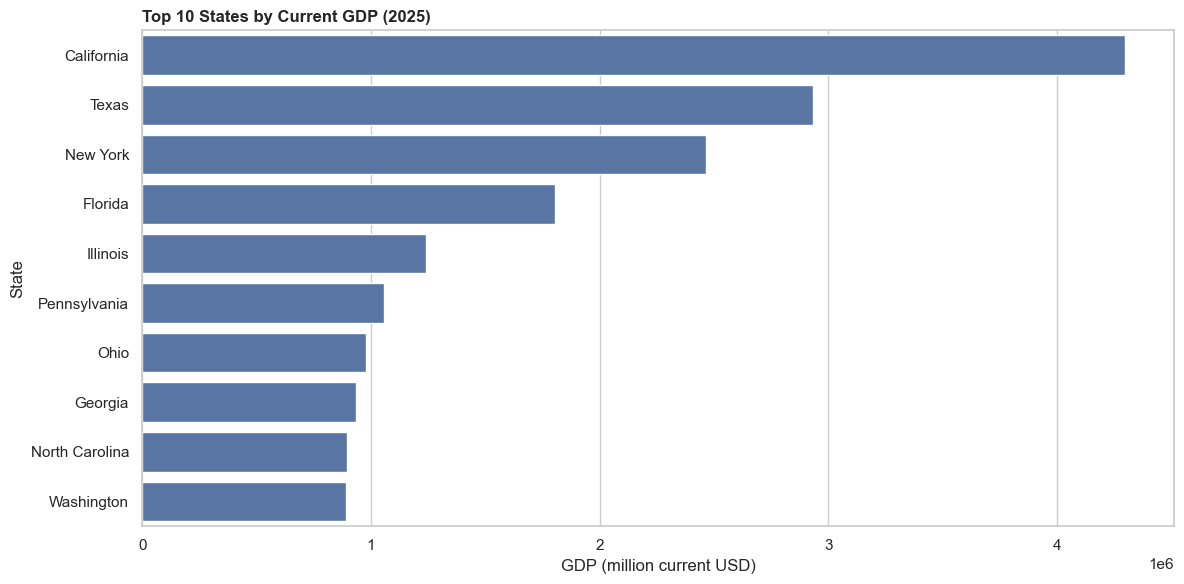

In [153]:
plt.figure(figsize=(12, 6))
sns.barplot(data=top10_gdp, x="gdp_current_musd", y="state_name")
plt.title(f"Top 10 States by Current GDP ({latest_year})")
plt.xlabel("GDP (million current USD)")
plt.ylabel("State")
plt.tight_layout()
plt.show()

### 5.14 Bar chart: Bottom 10 states by GDP

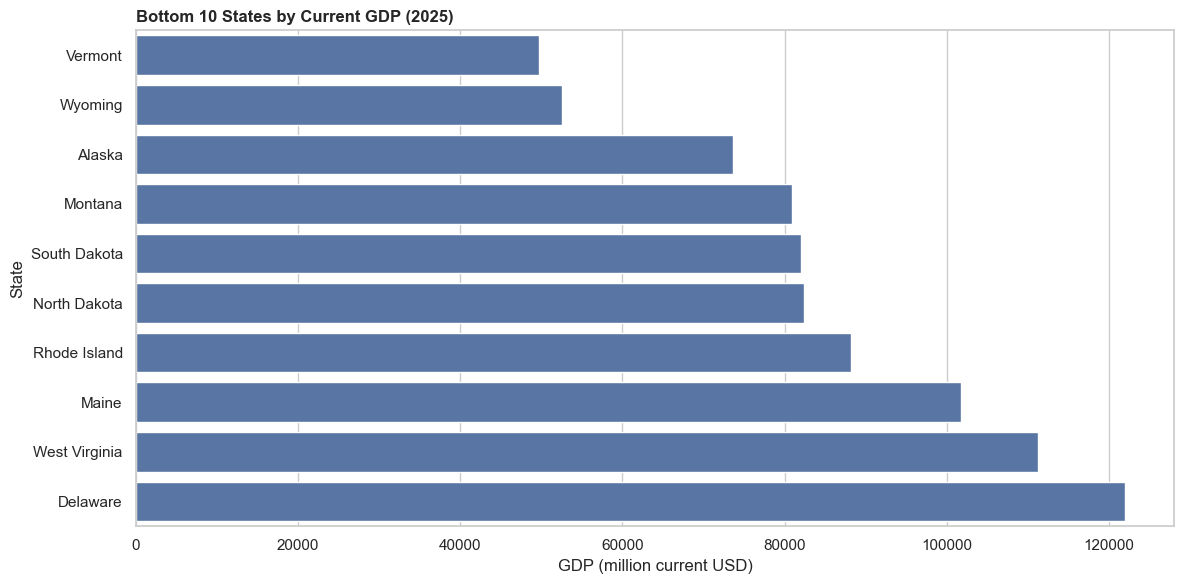

In [154]:
plt.figure(figsize=(12, 6))
sns.barplot(data=bottom10_gdp, x="gdp_current_musd", y="state_name")
plt.title(f"Bottom 10 States by Current GDP ({latest_year})")
plt.xlabel("GDP (million current USD)")
plt.ylabel("State")
plt.tight_layout()
plt.show()

### 5.15 GDP trend over time

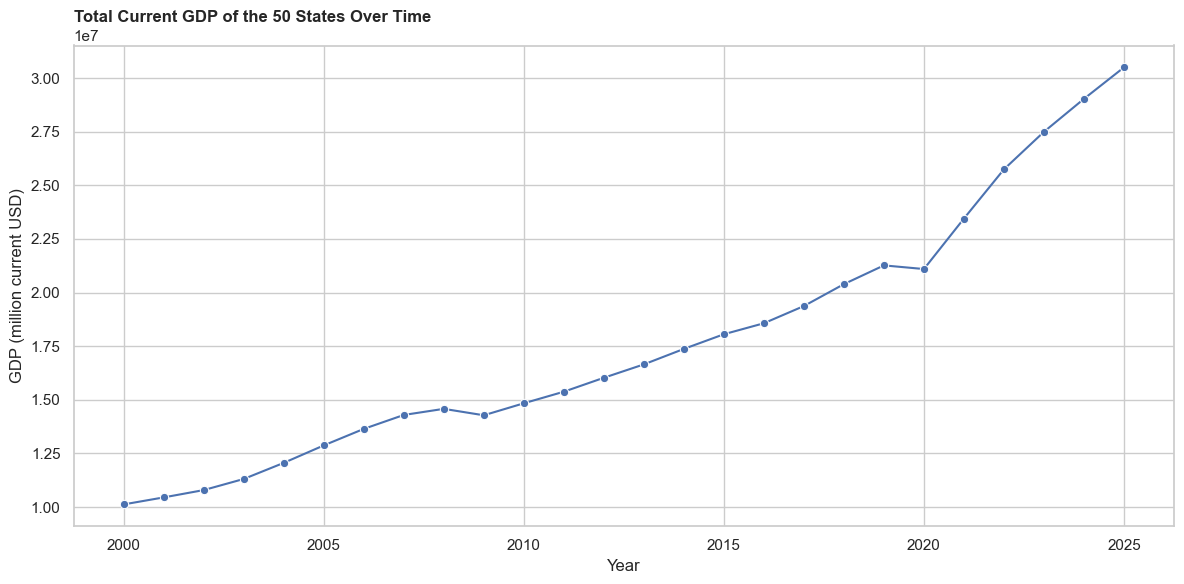

,year,gdp_current_musd
0,2000,"10,123,768.30"
1,2001,"10,450,027.70"
2,2002,"10,791,430.00"
3,2003,"11,309,638.00"
4,2004,"12,060,634.20"


In [155]:
# Total GDP of the 50 states for each year
yearly_gdp = states.groupby("year")["gdp_current_musd"].sum().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=yearly_gdp, x="year", y="gdp_current_musd", marker="o")
plt.title("Total Current GDP of the 50 States Over Time")
plt.xlabel("Year")
plt.ylabel("GDP (million current USD)")
plt.tight_layout()
plt.show()

display(yearly_gdp.head())

### 5.16 Population trend over time

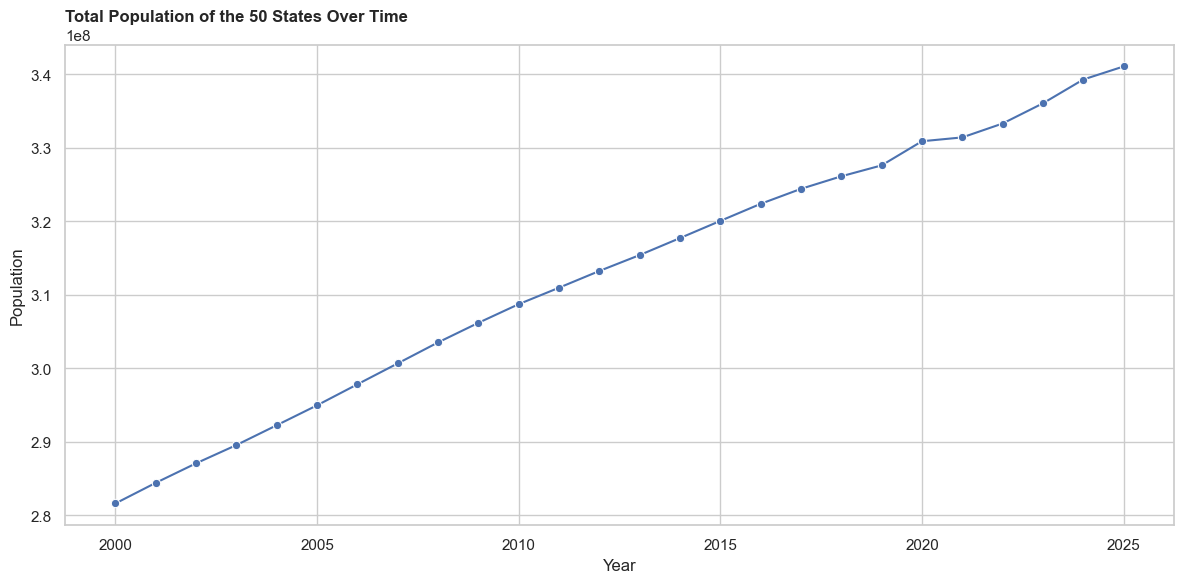

In [156]:
yearly_population = states.groupby("year")["population"].sum().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=yearly_population, x="year", y="population", marker="o")
plt.title("Total Population of the 50 States Over Time")
plt.xlabel("Year")
plt.ylabel("Population")
plt.tight_layout()
plt.show()

### 5.17 Compare GDP and population trends

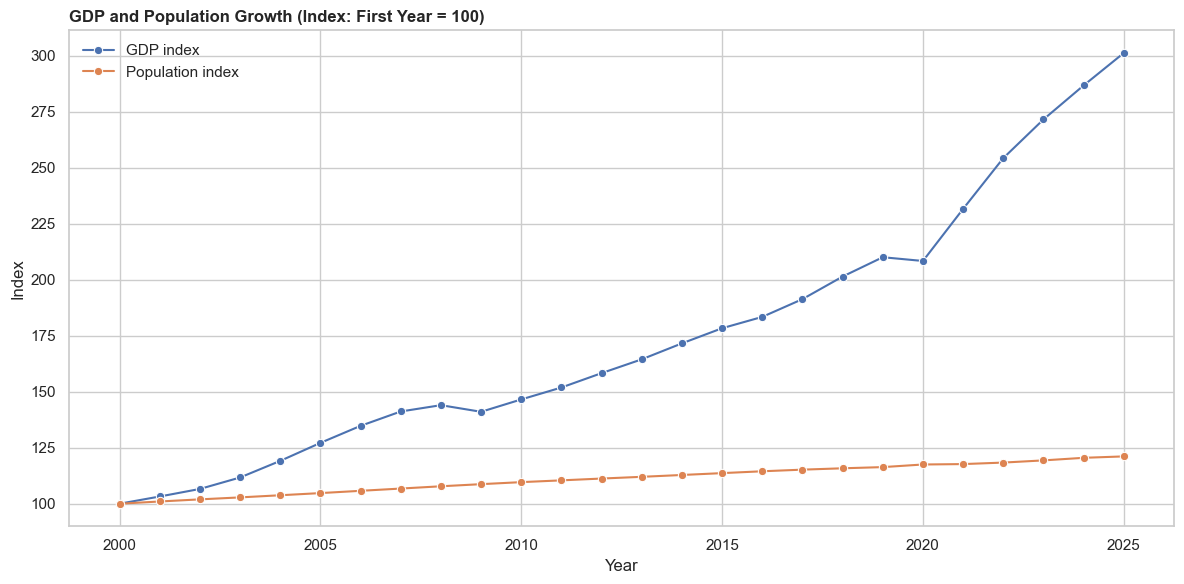

In [157]:
# Normalize both series to their first year so they can be compared on one chart
comparison = pd.concat(
    [
        yearly_gdp.set_index("year")["gdp_current_musd"],
        yearly_population.set_index("year")["population"]
    ],
    axis=1
).reset_index()
comparison["GDP index"] = comparison["gdp_current_musd"] / comparison["gdp_current_musd"].iloc[0] * 100
comparison["Population index"] = comparison["population"] / comparison["population"].iloc[0] * 100

plt.figure(figsize=(12, 6))
sns.lineplot(data=comparison, x="year", y="GDP index", label="GDP index", marker="o")
sns.lineplot(data=comparison, x="year", y="Population index", label="Population index", marker="o")
plt.title("GDP and Population Growth (Index: First Year = 100)")
plt.xlabel("Year")
plt.ylabel("Index")
plt.tight_layout()
plt.show()

### 5.18 Correlation between GDP and population

,gdp_current_musd,population,gdp_per_capita
gdp_current_musd,1.00,0.93,0.37
population,0.93,1.00,0.15
gdp_per_capita,0.37,0.15,1.00


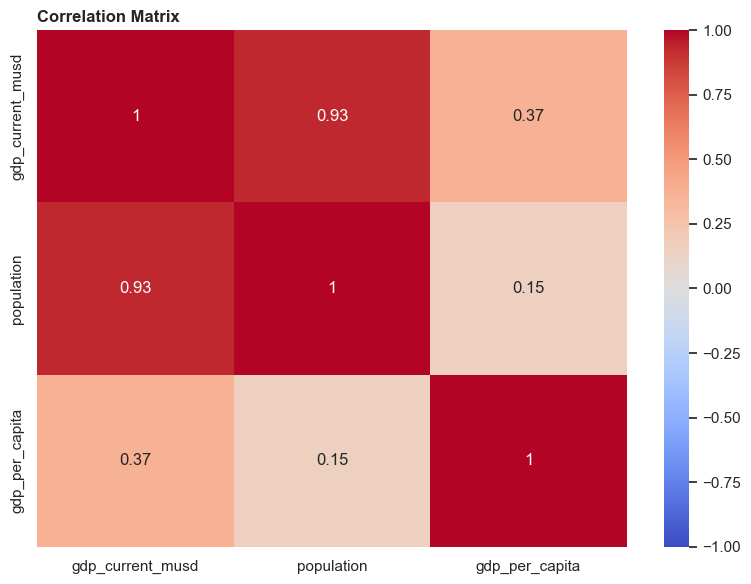

In [158]:
correlation = states[["gdp_current_musd", "population", "gdp_per_capita"]].corr()
display(correlation)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

### 5.19 GDP distribution

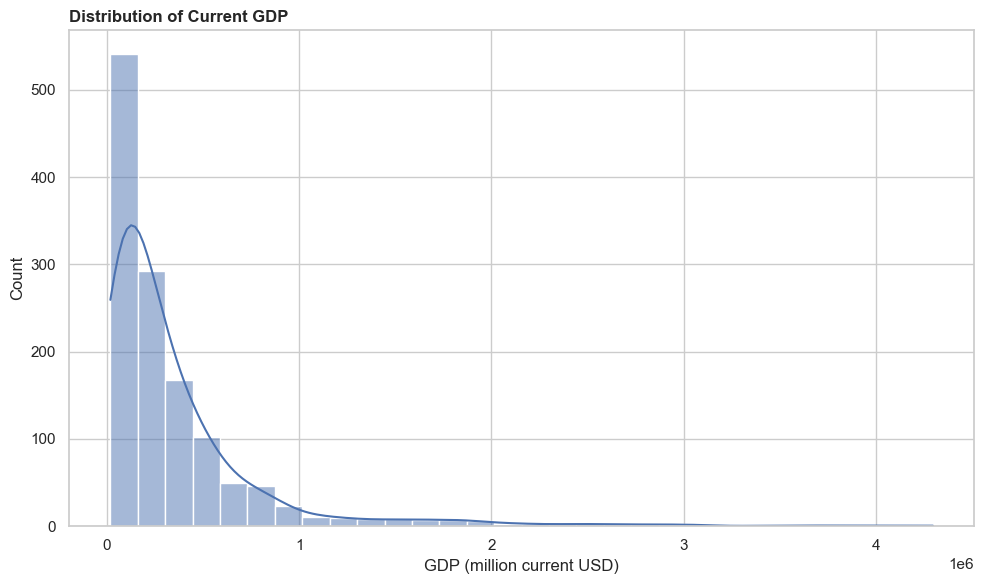

In [159]:
plt.figure(figsize=(10, 6))
sns.histplot(states["gdp_current_musd"], bins=30, kde=True)
plt.title("Distribution of Current GDP")
plt.xlabel("GDP (million current USD)")
plt.tight_layout()
plt.show()

### 5.20 Boxplot and outlier check using IQR

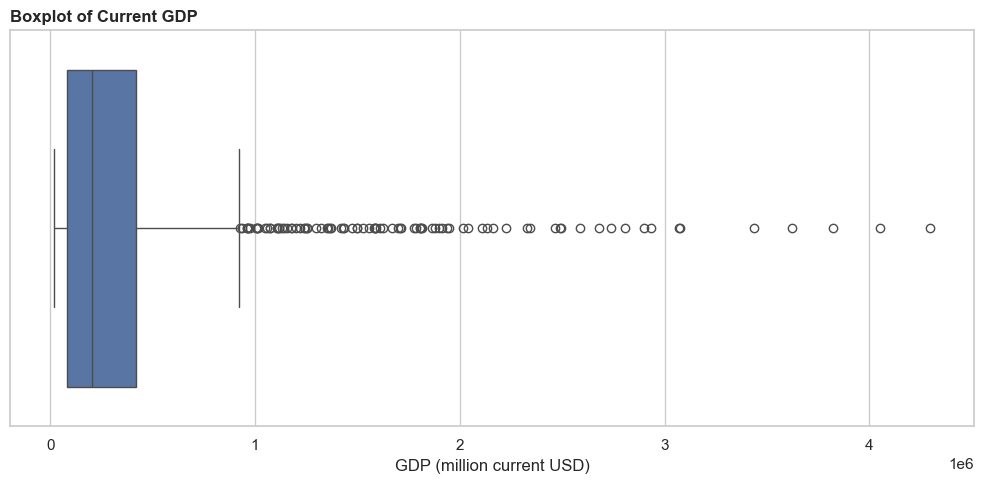

Lower limit: -423923.1
Upper limit: 924923.5
Number of outlier rows: 90


,year,state_name,gdp_current_musd
4,2000,California,"1,354,791.30"
56,2001,California,"1,373,270.80"
108,2002,California,"1,419,321.80"
160,2003,California,"1,498,578.00"
212,2004,California,"1,585,081.40"
242,2004,New York,"958,565.30"
264,2005,California,"1,698,858.40"
294,2005,New York,"1,009,851.00"
303,2005,Texas,"1,003,745.90"
316,2006,California,"1,812,161.60"


In [160]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=states["gdp_current_musd"])
plt.title("Boxplot of Current GDP")
plt.xlabel("GDP (million current USD)")
plt.tight_layout()
plt.show()

Q1 = states["gdp_current_musd"].quantile(0.25)
Q3 = states["gdp_current_musd"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = states[
    (states["gdp_current_musd"] < lower_limit) |
    (states["gdp_current_musd"] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of outlier rows:", len(outliers))
display(outliers[["year", "state_name", "gdp_current_musd"]].head(20))


### 5.21 GDP by state over time (selected states)

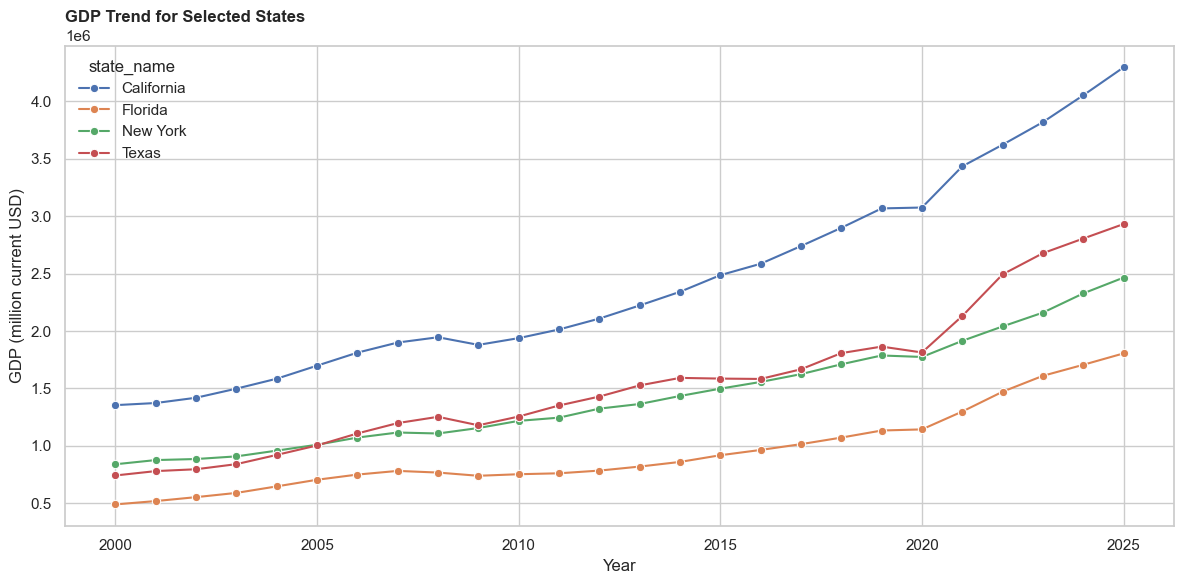

In [161]:
selected_states = ["California", "Texas", "Florida", "New York"]

selected_data = states[states["state_name"].isin(selected_states)]

plt.figure(figsize=(12, 6))
sns.lineplot(data=selected_data, x="year", y="gdp_current_musd",
             hue="state_name", marker="o")
plt.title("GDP Trend for Selected States")
plt.xlabel("Year")
plt.ylabel("GDP (million current USD)")
plt.tight_layout()
plt.show()

### 5.22 Year-over-year GDP growth

,year,state_name,gdp_current_musd,gdp_growth_percent
0,2000,Alaska,"26,934.00",NaN
52,2001,Alaska,"28,660.90",6.41
104,2002,Alaska,"29,884.50",4.27
156,2003,Alaska,"32,115.80",7.47
208,2004,Alaska,"35,389.50",10.19
260,2005,Alaska,"40,459.90",14.33
312,2006,Alaska,"44,951.70",11.10
364,2007,Alaska,"49,456.40",10.02
416,2008,Alaska,"55,246.70",11.71
468,2009,Alaska,"50,165.90",-9.20


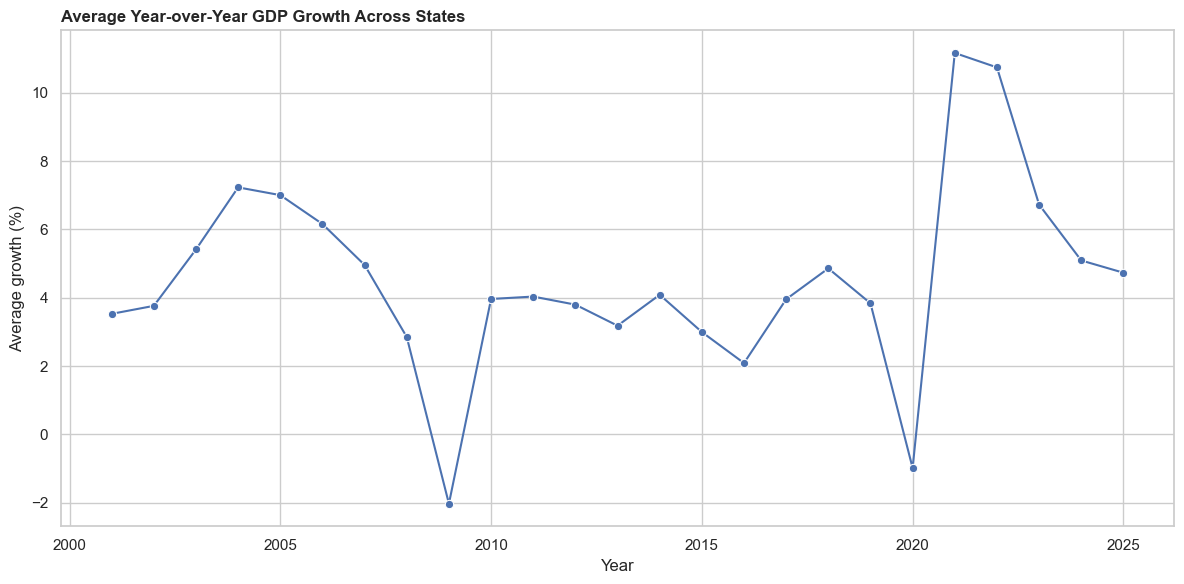

In [162]:
states = states.sort_values(["state_code", "year"])

states["gdp_growth_percent"] = (
    states.groupby("state_code")["gdp_current_musd"].pct_change() * 100)

display(states[["year", "state_name", "gdp_current_musd", "gdp_growth_percent"]].head(15))

# Average growth rate by year across states
average_growth = states.groupby("year")["gdp_growth_percent"].mean().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=average_growth, x="year", y="gdp_growth_percent", marker="o")
plt.title("Average Year-over-Year GDP Growth Across States")
plt.xlabel("Year")
plt.ylabel("Average growth (%)")
plt.tight_layout()
plt.show()

### 5.23 Top 10 states by population

,state_name,state_code,year,population,gdp_current_musd
1304,California,CA,2025,"39,355,309.00","4,297,449.80"
1343,Texas,TX,2025,"31,709,821.00","2,932,343.60"
1309,Florida,FL,2025,"23,462,518.00","1,805,620.20"
1334,New York,NY,2025,"20,002,427.00","2,465,749.30"
1338,Pennsylvania,PA,2025,"13,059,432.00","1,056,488.20"
1314,Illinois,IL,2025,"12,719,141.00","1,240,982.70"
1335,Ohio,OH,2025,"11,900,510.00","976,871.70"
1310,Georgia,GA,2025,"11,302,748.00","936,086.70"
1327,North Carolina,NC,2025,"11,197,968.00","895,919.20"
1322,Michigan,MI,2025,"10,127,884.00","733,887.10"


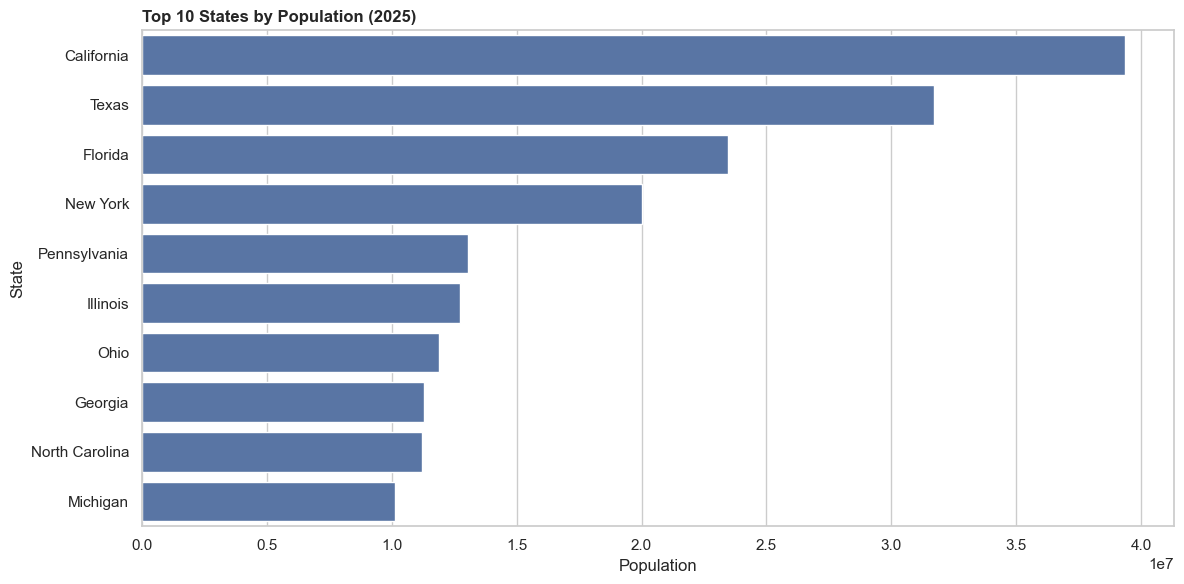

In [163]:
top10_population = latest_data.nlargest(10, "population")[
    ["state_name", "state_code", "year", "population", "gdp_current_musd"]]
display(top10_population)

plt.figure(figsize=(12, 6))
sns.barplot(data=top10_population, x="population", y="state_name")
plt.title(f"Top 10 States by Population ({latest_year})")
plt.xlabel("Population")
plt.ylabel("State")
plt.tight_layout()
plt.show()

### 5.24 Bottom 10 states by population

,state_name,state_code,year,population,gdp_current_musd
1351,Wyoming,WY,2025,"588,753.00","52,491.20"
1347,Vermont,VT,2025,"644,663.00","49,657.50"
1300,Alaska,AK,2025,"737,270.00","73,634.80"
1328,North Dakota,ND,2025,"799,358.00","82,349.80"
1341,South Dakota,SD,2025,"935,094.00","82,001.90"
1308,Delaware,DE,2025,"1,059,952.00","121,940.00"
1339,Rhode Island,RI,2025,"1,114,521.00","88,240.60"
1326,Montana,MT,2025,"1,144,694.00","80,945.20"
1321,Maine,ME,2025,"1,414,874.00","101,726.20"
1330,New Hampshire,NH,2025,"1,415,342.00","128,278.60"


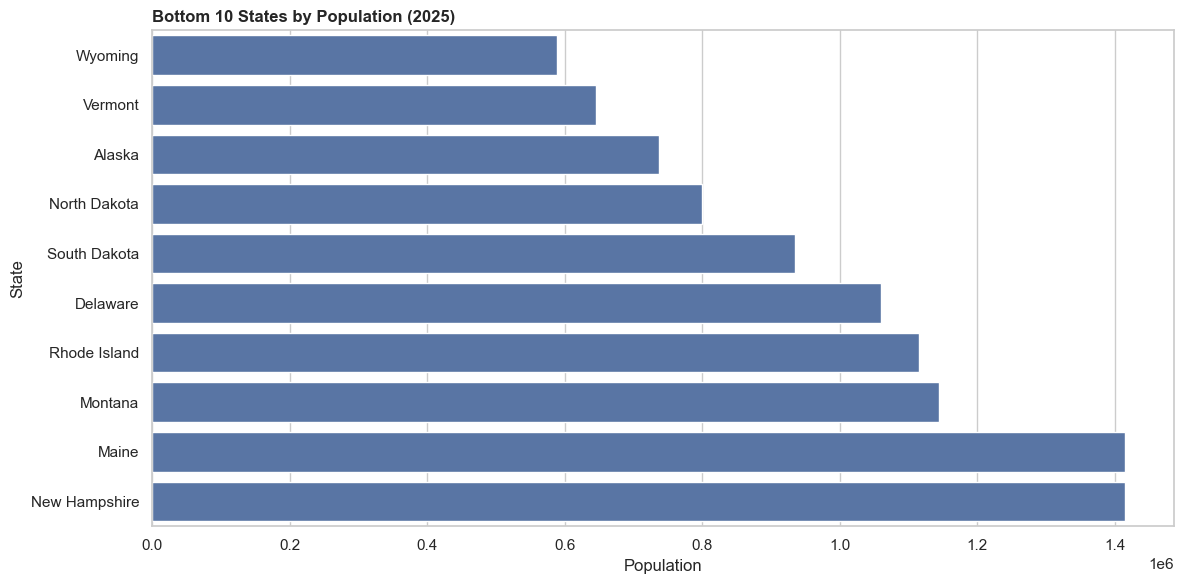

In [164]:
bottom10_population = latest_data.nsmallest(10, "population")[
    ["state_name", "state_code", "year", "population", "gdp_current_musd"]]
display(bottom10_population)

plt.figure(figsize=(12, 6))
sns.barplot(data=bottom10_population, x="population", y="state_name")
plt.title(f"Bottom 10 States by Population ({latest_year})")
plt.xlabel("Population")
plt.ylabel("State")
plt.tight_layout()
plt.show()

### 5.25 Population trend for selected states

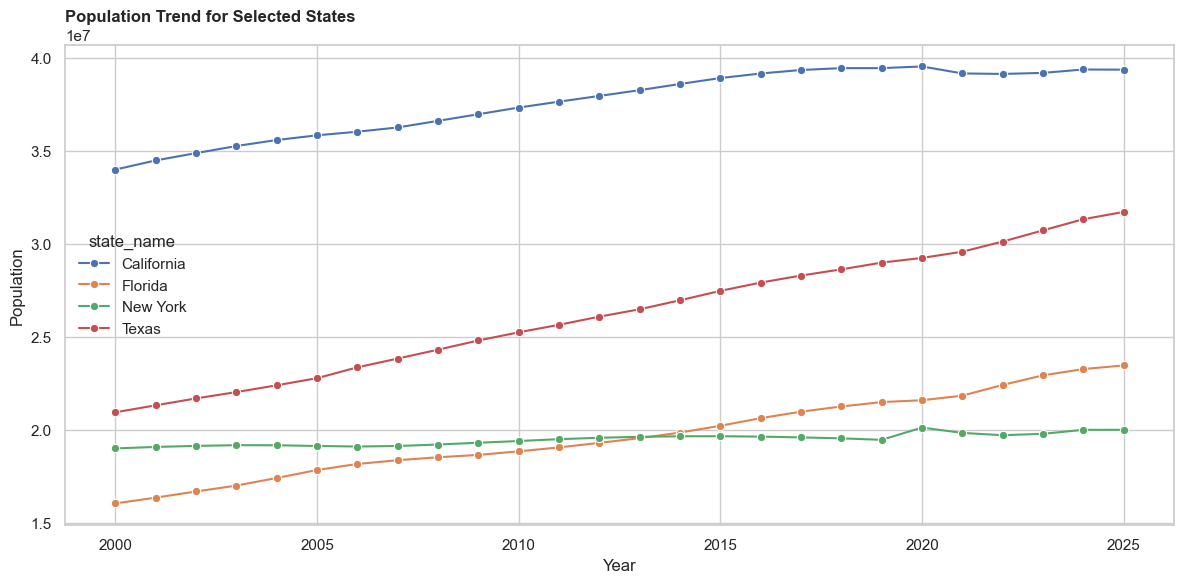

In [165]:
# selected_states is defined in Section 5.21 above
selected_population = states[states["state_name"].isin(selected_states)]

plt.figure(figsize=(12, 6))
sns.lineplot(data=selected_population, x="year", y="population",
             hue="state_name", marker="o")
plt.title("Population Trend for Selected States")
plt.xlabel("Year")
plt.ylabel("Population")
plt.tight_layout()
plt.show()

### 5.26 Relationship between population and GDP

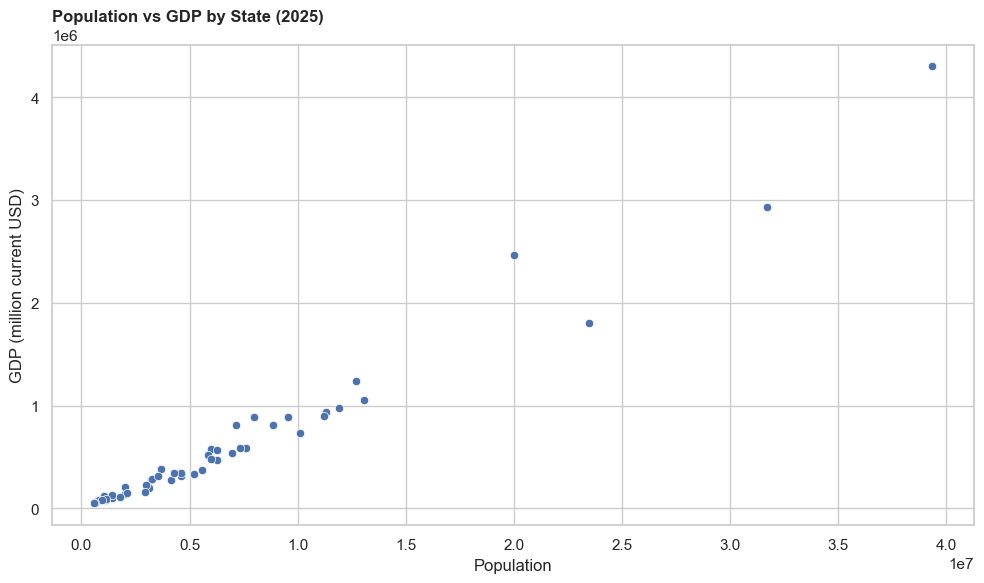

In [166]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=latest_data, x="population", y="gdp_current_musd")
plt.title(f"Population vs GDP by State ({latest_year})")
plt.xlabel("Population")
plt.ylabel("GDP (million current USD)")
plt.tight_layout()
plt.show()

### 5.27 Bar chart: Top 10 states by GDP per capita

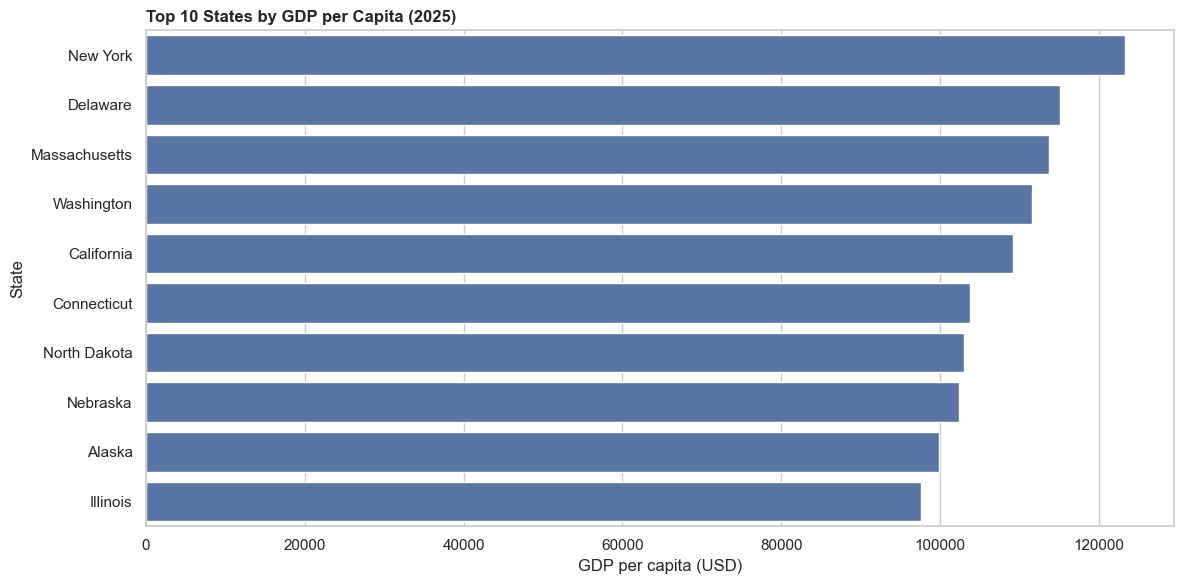

In [167]:
plt.figure(figsize=(12, 6))
sns.barplot(data=top10_per_capita, x="gdp_per_capita", y="state_name")
plt.title(f"Top 10 States by GDP per Capita ({latest_year})")
plt.xlabel("GDP per capita (USD)")
plt.ylabel("State")
plt.tight_layout()
plt.show()

### 5.28 Population distribution

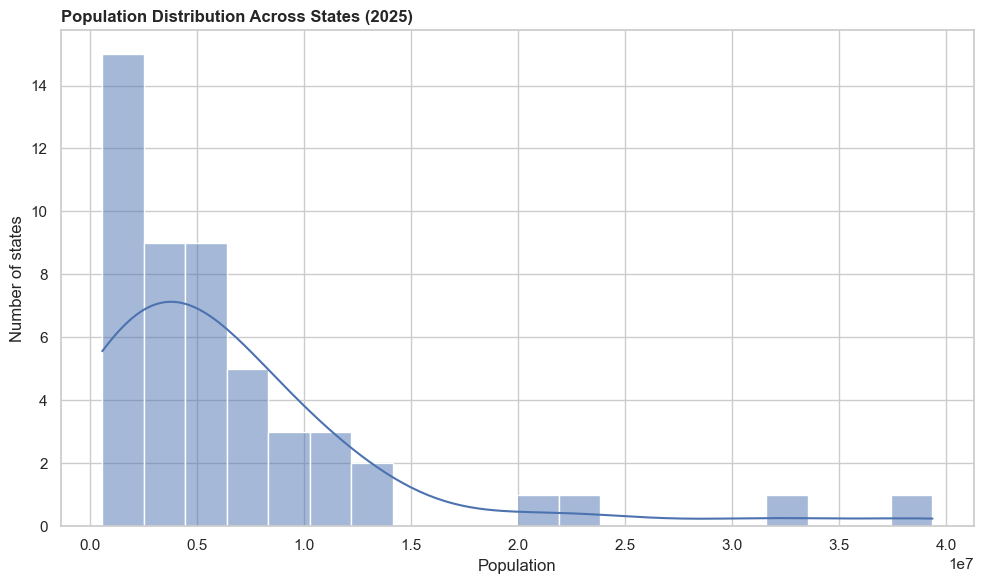

In [168]:
plt.figure(figsize=(10, 6))
sns.histplot(data=latest_data, x="population", bins=20, kde=True)
plt.title(f"Population Distribution Across States ({latest_year})")
plt.xlabel("Population")
plt.ylabel("Number of states")
plt.tight_layout()
plt.show()

In [169]:
# The complete unified dataset was already saved once at the end of Section 3.6.
print("Using the unified dataset: unified_dataset.csv")

Using the unified dataset: unified_dataset.csv


## 6. Visualisation and Insights

In [170]:
# ---- shared plot style ----
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6")
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.figsize": (11, 5.5),
})

def style(ax, title, xlabel="", ylabel=""):
    ax.set_title(title, pad=12)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_axisbelow(True)


### 6.1 Generation mix: gas and renewables replaced coal

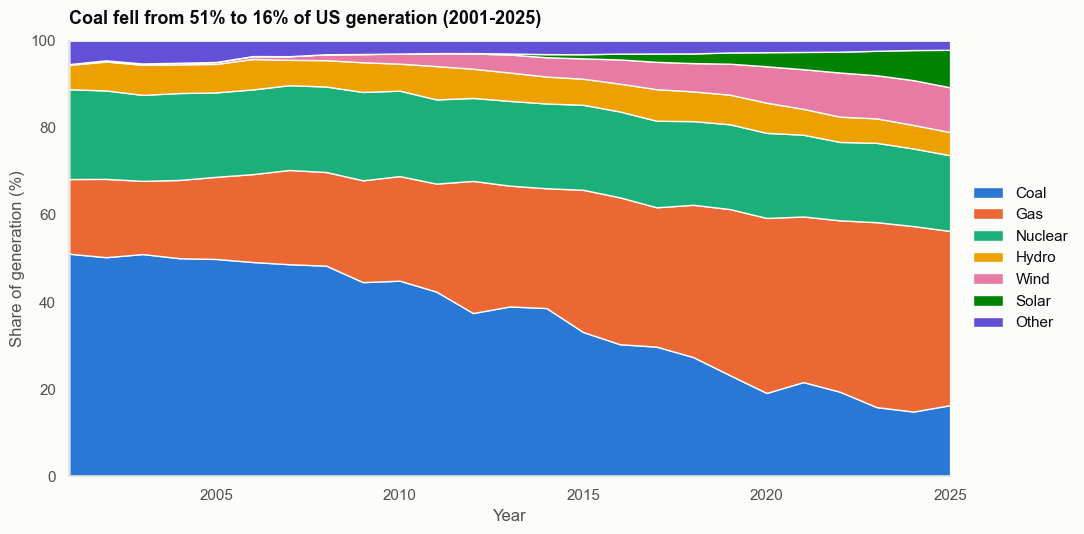

In [171]:
groups = {"Coal": ["Coal"], "Gas": ["Gas"], "Nuclear": ["Nuclear"], "Hydro": ["Hydro"],
          "Wind": ["Wind"], "Solar": ["Solar"],
          "Other": ["Other fossil", "Bioenergy", "Other renewables"]}
mix = pd.DataFrame({k: share[v].sum(axis=1) for k, v in groups.items()})

fig, ax = plt.subplots()
ax.stackplot(mix.index, mix.T.values, labels=mix.columns,
             colors=[BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET],
             edgecolor=SURFACE, linewidth=1)
ax.set_xlim(mix.index.min(), mix.index.max()); ax.set_ylim(0, 100)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
style(ax, "Coal fell from 51% to 16% of US generation (2001-2025)", "Year", "Share of generation (%)")
plt.tight_layout(); plt.show()


**Comment:** gas (17% to 40%) and wind + solar (0.2% to 18.9%) filled the space that coal left (51% to 16%). Nuclear stayed roughly flat in share (20.6% to 17.4%).

### 6.2 Reported consumption vs generation

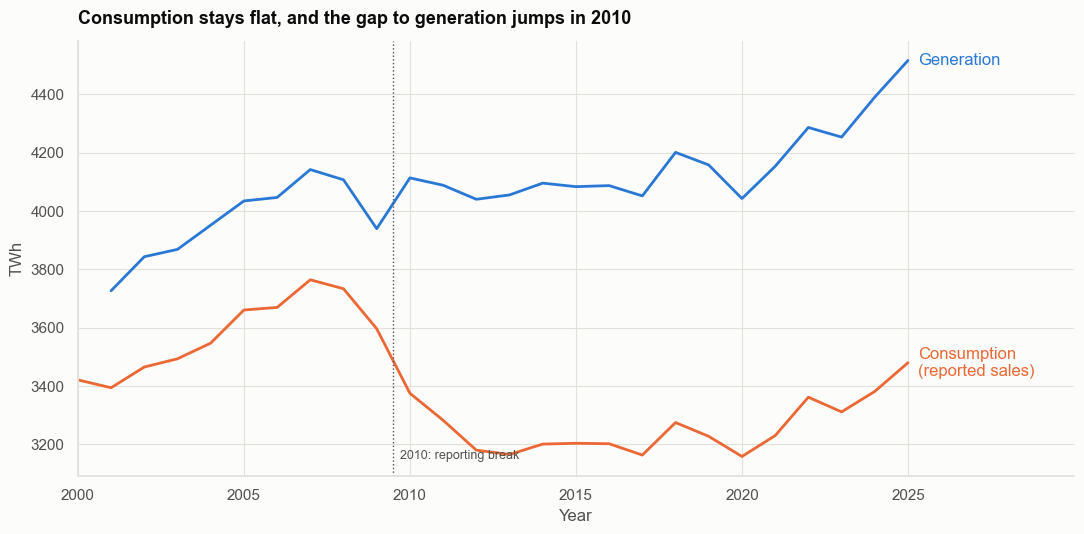

In [172]:
fig, ax = plt.subplots()
ax.plot(nat.index, nat["gen_twh"], color=BLUE, lw=2)
ax.plot(nat.index, nat["cons_twh"], color=ORANGE, lw=2)
ax.axvline(2009.5, color=MUTED, lw=1, ls=":")
ax.text(2009.7, ax.get_ylim()[0] + 60, "2010: reporting break", color=MUTED, fontsize=9)
ax.text(nat.index.max() + 0.3, nat["gen_twh"].iloc[-1], "Generation", color=BLUE, va="center")
ax.text(nat.index.max() + 0.3, nat["cons_twh"].iloc[-1], "Consumption\n(reported sales)", color=ORANGE, va="center")
ax.set_xlim(nat.index.min(), nat.index.max() + 5)
ax.set_xticks(range(2000, 2026, 5))
style(ax, "Consumption stays flat, and the gap to generation jumps in 2010", "Year", "TWh")
plt.tight_layout(); plt.show()


**Comment:** generation grew about 21% while reported consumption stayed flat. Before 2010 about 9% of generation was not counted as sales (losses and own use). The ratio then falls from 91% (2009) to 82% (2010), which is the reporting break, not a real change in demand.

### 6.3 The break: 14 affected states vs the other 37

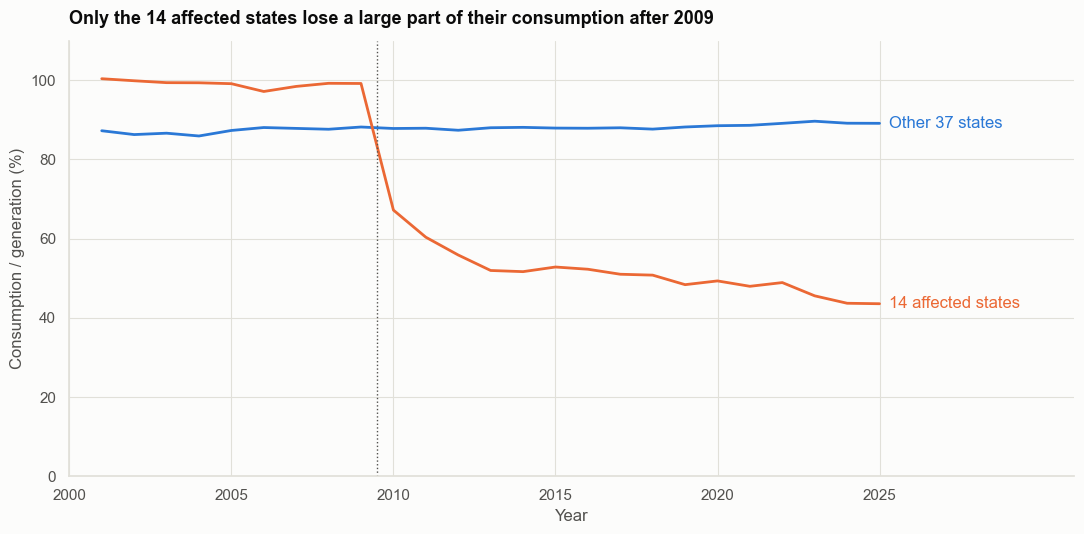

In [173]:
fig, ax = plt.subplots()
ax.plot(r_un.index, r_un, color=BLUE, lw=2)
ax.plot(r_aff.index, r_aff, color=ORANGE, lw=2)
ax.axvline(2009.5, color=MUTED, lw=1, ls=":")
ax.set_ylim(0, 110)
ax.text(r_un.index.max() + 0.3, r_un.dropna().iloc[-1], "Other 37 states", color=BLUE, va="center")
ax.text(r_aff.index.max() + 0.3, r_aff.dropna().iloc[-1], "14 affected states", color=ORANGE, va="center")
ax.set_xlim(r_un.index.min(), r_un.index.max() + 6)
ax.set_xticks(range(2000, 2026, 5))
style(ax, "Only the 14 affected states lose a large part of their consumption after 2009",
      "Year", "Consumption / generation (%)")
plt.tight_layout(); plt.show()


**Comment:** the other 37 states stay near 88% every year, while the 14 affected states fall from about 99% to 52-67%. National generation did not fall in 2010 (3,940 to 4,114 TWh), so the drop is in what is reported.

### 6.4 Electricity prices by sector (sales-weighted, nominal)

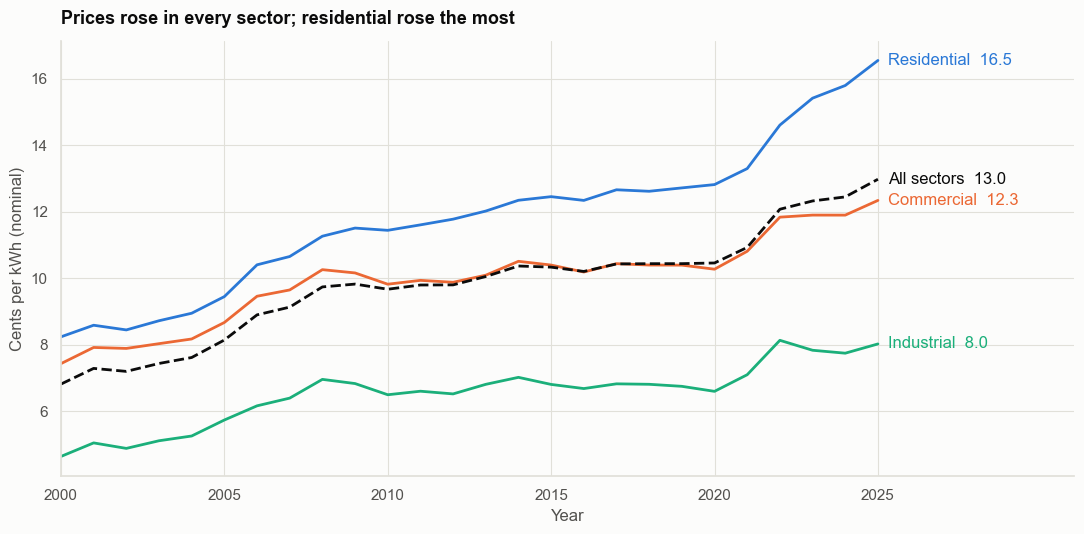

In [174]:
sectors = {"res": ("Residential", BLUE), "com": ("Commercial", ORANGE),
           "ind": ("Industrial", AQUA), "total": ("All sectors", INK)}
yr = cons.groupby("year")[[f"{s}_revenues" for s in sectors] + [f"{s}_sales" for s in sectors]].sum()

fig, ax = plt.subplots()
for s, (label, colour) in sectors.items():
    price = yr[f"{s}_revenues"] / yr[f"{s}_sales"] * 100      # cents per kWh
    ax.plot(price.index, price, color=colour, lw=2, ls="--" if s == "total" else "-")
    ax.text(price.index.max() + 0.3, price.iloc[-1], f"{label}  {price.iloc[-1]:.1f}", color=colour, va="center")
ax.set_xlim(yr.index.min(), yr.index.max() + 6)
ax.set_xticks(range(2000, 2026, 5))
style(ax, "Prices rose in every sector; residential rose the most", "Year", "Cents per kWh (nominal)")
plt.tight_layout(); plt.show()


**Comment:** residential prices rose 101%, industrial 73% and commercial 66% (nominal, so part of this is general inflation). Residential is now the most expensive sector by a wide margin.

### 6.5 Largest electricity consumers in 2025

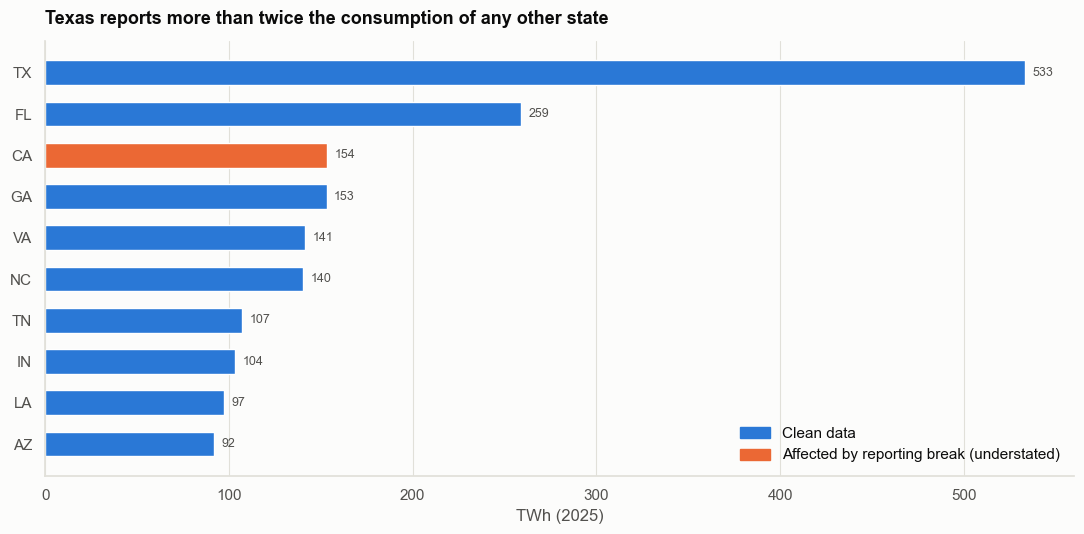

In [175]:
c25 = cons[cons["year"] == 2025].set_index("state_code")
top = c25.nlargest(10, "total_sales_twh").sort_values("total_sales_twh")
colours = [ORANGE if a else BLUE for a in top["affected_break"]]

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(top.index, top["total_sales_twh"], color=colours, height=0.6)
for y, v in enumerate(top["total_sales_twh"]):
    ax.text(v + 4, y, f"{v:,.0f}", va="center", color=MUTED, fontsize=9)
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=BLUE, label="Clean data"),
                   Patch(color=ORANGE, label="Affected by reporting break (understated)")],
          loc="lower right")
style(ax, "Texas reports more than twice the consumption of any other state", "TWh (2025)")
plt.tight_layout(); plt.show()


**Comment:** Texas (533 TWh) is more than twice Florida (259 TWh). California is third only because the break understates its consumption, which is why it is orange.

### 6.6 Which states moved away from coal, and where wind and solar lead

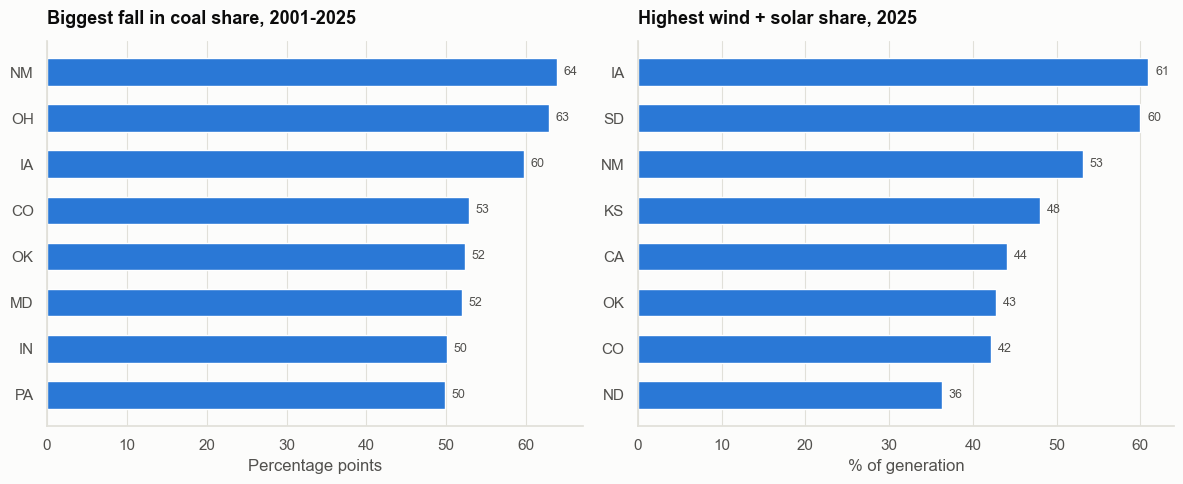

In [176]:
big = res[res["total25_twh"] >= MIN_TWH]
coal_drop = (-big["coal_change_pp"]).nlargest(8).sort_values()
vre_top = big["vre_2025"].nlargest(8).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, ser, title, xl in [
    (axes[0], coal_drop, "Biggest fall in coal share, 2001-2025", "Percentage points"),
    (axes[1], vre_top, "Highest wind + solar share, 2025", "% of generation")]:
    ax.barh(ser.index, ser.values, color=BLUE, height=0.6)
    for y, v in enumerate(ser.values):
        ax.text(v + 0.8, y, f"{v:.0f}", va="center", color=MUTED, fontsize=9)
    ax.grid(axis="y", visible=False)
    style(ax, title, xl)
plt.tight_layout(); plt.show()


**Comment:** coal was replaced by gas in Ohio (-62.9 points of coal, +54.3 of gas) and by wind and solar in Iowa (61% wind + solar) and New Mexico (53%). Iowa, New Mexico, Colorado and Oklahoma appear on both lists, while Ohio, Pennsylvania, Maryland and Indiana moved mostly to gas, so there was no single path away from coal.

### 6.7 Who uses the electricity: demand by sector (37 clean states)

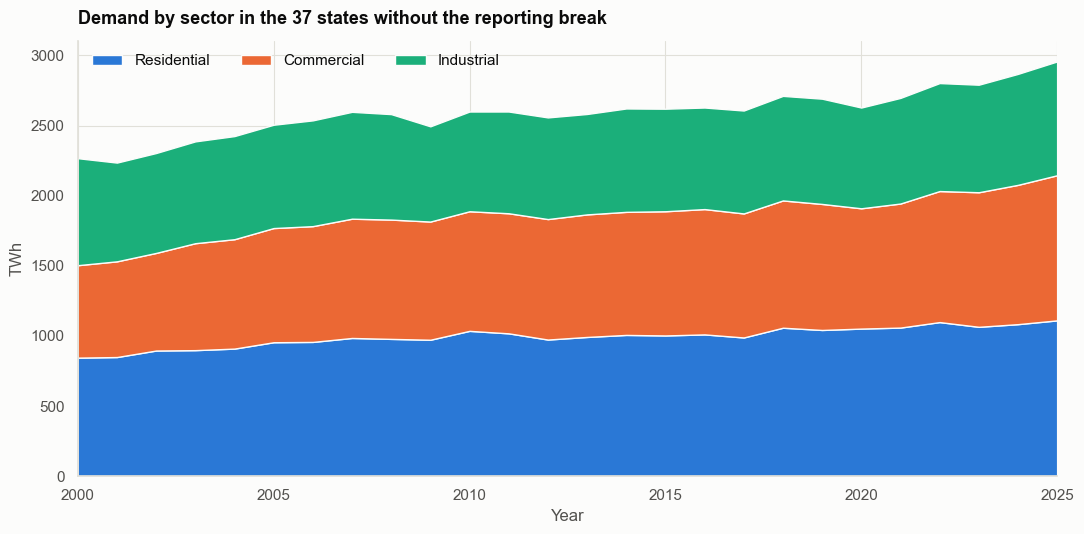

In [177]:
sec = cons[~cons["affected_break"]].groupby("year")[["res_sales_twh", "com_sales_twh", "ind_sales_twh"]].sum()

fig, ax = plt.subplots()
ax.stackplot(sec.index, sec.T.values, labels=["Residential", "Commercial", "Industrial"],
             colors=[BLUE, ORANGE, AQUA], edgecolor=SURFACE, linewidth=1)
ax.set_xlim(sec.index.min(), sec.index.max())
ax.legend(loc="upper left", ncol=3)
style(ax, "Demand by sector in the 37 states without the reporting break", "Year", "TWh")
plt.tight_layout(); plt.show()


**Comment:** in 2025 residential is 37.6% of demand, commercial 35.0% and industrial 27.4% in these states. The three sectors move slowly, so the national total is flat for a long time.

### 6.8 Consumption growth by state, 2000-2025 (37 clean states)

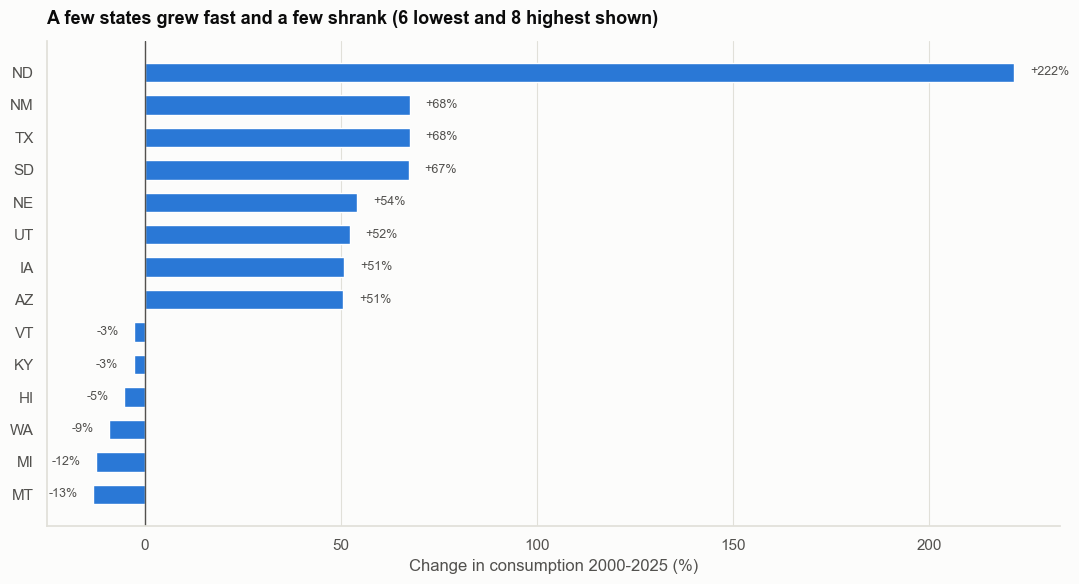

In [178]:
pc = cons.pivot(index="state_code", columns="year", values="total_sales_twh").drop(affected)
growth = ((pc[2025] / pc[2000] - 1) * 100).sort_values()
show = pd.concat([growth.head(6), growth.tail(8)])
show = show[~show.index.duplicated()]

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(show.index, show.values, color=BLUE, height=0.6)
ax.axvline(0, color=MUTED, lw=1)
for y, v in enumerate(show.values):
    ax.text(v + (4 if v >= 0 else -4), y, f"{v:+.0f}%", va="center",
            ha="left" if v >= 0 else "right", color=MUTED, fontsize=9)
ax.grid(axis="y", visible=False)
style(ax, "A few states grew fast and a few shrank (6 lowest and 8 highest shown)", "Change in consumption 2000-2025 (%)")
plt.tight_layout(); plt.show()


**Comment:** North Dakota grew the most (+222%), followed by Texas and New Mexico (+68% each). Montana (-13%), Michigan (-12%) and Washington (-9%) shrank. Growth is concentrated in a few states, so the national average hides large differences.

### 6.9 Emissions by source (pollutants)

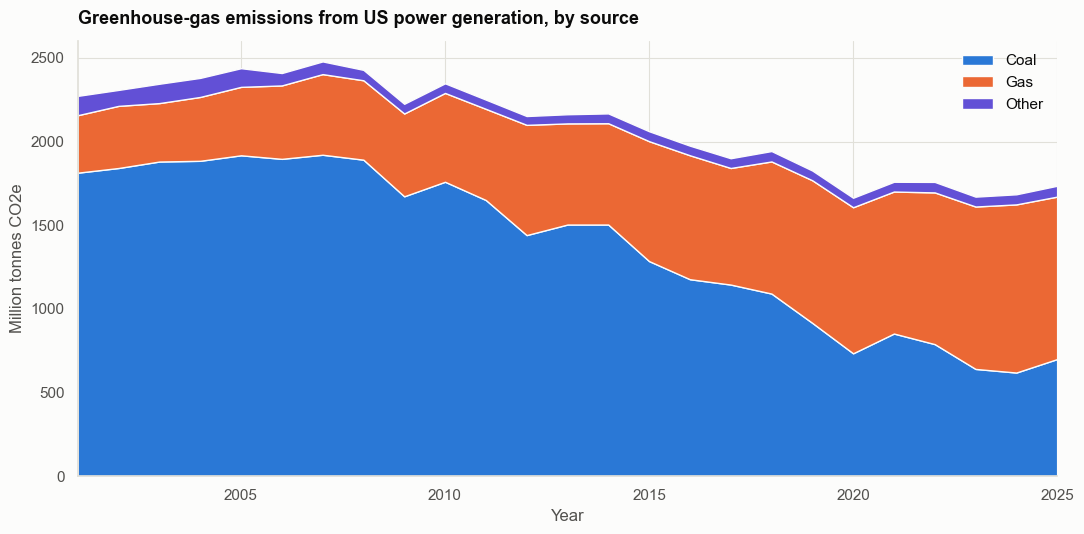

In [179]:
em = emis[emis["state_code"] != "PR"].copy()
em["group"] = em["source"].where(em["source"].isin(["Coal", "Gas"]), "Other")
em_year = em.pivot_table(index="year", columns="group", values="emissions_mtco2e", aggfunc="sum").fillna(0)
em_year = em_year[[c for c in ["Coal", "Gas", "Other"] if c in em_year.columns]]
em_colour = {"Coal": BLUE, "Gas": ORANGE, "Other": VIOLET}

fig, ax = plt.subplots()
ax.stackplot(em_year.index, em_year.T.values, labels=em_year.columns,
             colors=[em_colour[c] for c in em_year.columns], edgecolor=SURFACE, linewidth=1)
ax.set_xlim(em_year.index.min(), em_year.index.max())
ax.legend(loc="upper right")
style(ax, "Greenhouse-gas emissions from US power generation, by source", "Year", "Million tonnes CO2e")
plt.tight_layout(); plt.show()


**Comment:** the data covers greenhouse gases only (CO2-equivalent), not SO2, NOx or particulates, so "pollutants" here means CO2e. Colours match plot 1 (coal blue, gas orange). Since coal fell from 51% to 16% of generation, the shrinking coal band is the main thing to look for.

### 6.10 Emissions intensity of US electricity

In [180]:
# Calculate emissions intensity directly from the unified dataset.
# Both emissions and generation are already stored by source in the same row.
energy_states = cons[cons["state_code"] != "PR"].copy()

emission_cols = [
    c for c in energy_states.columns
    if c.startswith("emissions_mtco2e__")
]
generation_cols = [
    c for c in energy_states.columns
    if c.startswith("generation_twh__")
]

by_year = pd.DataFrame({
    "emissions_mtco2e": energy_states.groupby("year")[emission_cols].sum().sum(axis=1),
    "generation_twh": energy_states.groupby("year")[generation_cols].sum().sum(axis=1)
})
intensity = (
    by_year["emissions_mtco2e"] / by_year["generation_twh"] * 1000
)

**Comment:** intensity is total emissions divided by total generation, so it falls when the mix gets cleaner even if generation grows. Read it together with plot 1: the fall of coal is what drives it.

### 6.11 Largest emitters in 2025

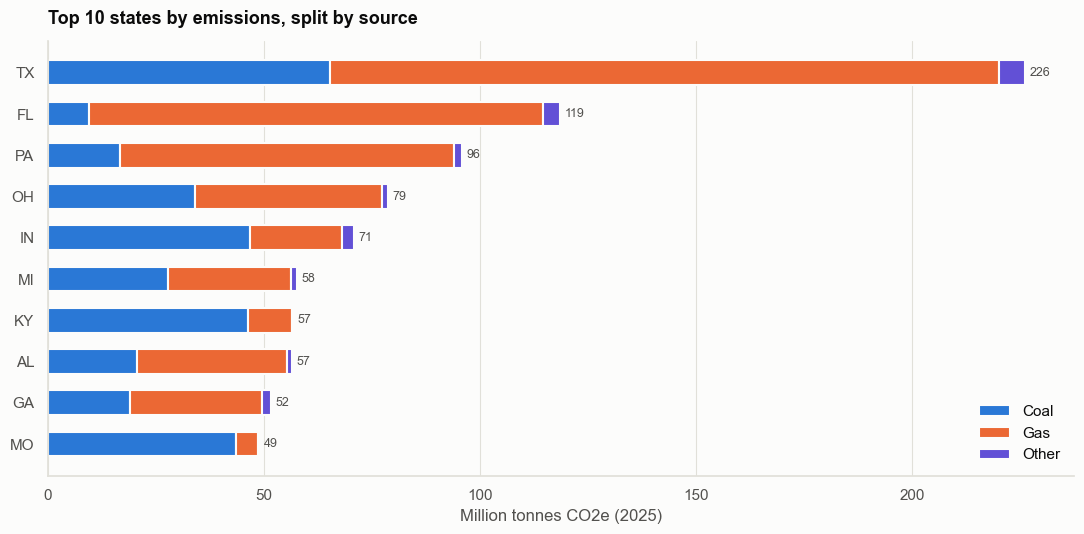

In [181]:
e25 = em[em["year"] == 2025].pivot_table(index="state_code", columns="group", values="emissions_mtco2e", aggfunc="sum").fillna(0)
for col in ["Coal", "Gas", "Other"]:
    if col not in e25.columns: e25[col] = 0
e25["total"] = e25[["Coal", "Gas", "Other"]].sum(axis=1)
top_e = e25.nlargest(10, "total").sort_values("total")

fig, ax = plt.subplots(figsize=(11, 5.5))
left = np.zeros(len(top_e))
for col in ["Coal", "Gas", "Other"]:
    ax.barh(top_e.index, top_e[col], left=left, color=em_colour[col], height=0.6,
            edgecolor=SURFACE, linewidth=1.5, label=col)
    left += top_e[col].values
for y, v in enumerate(top_e["total"]):
    ax.text(v + 1, y, f"{v:,.0f}", va="center", color=MUTED, fontsize=9)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
style(ax, "Top 10 states by emissions, split by source", "Million tonnes CO2e (2025)")
plt.tight_layout(); plt.show()


**Comment:** compare this ranking with the generation ranking (Texas is first with 596 TWh). A state that emits more than its generation suggests has a coal-heavy mix, and the colour split shows that directly.

### 6.12 Electricity use per person vs income (2025, 37 clean states)

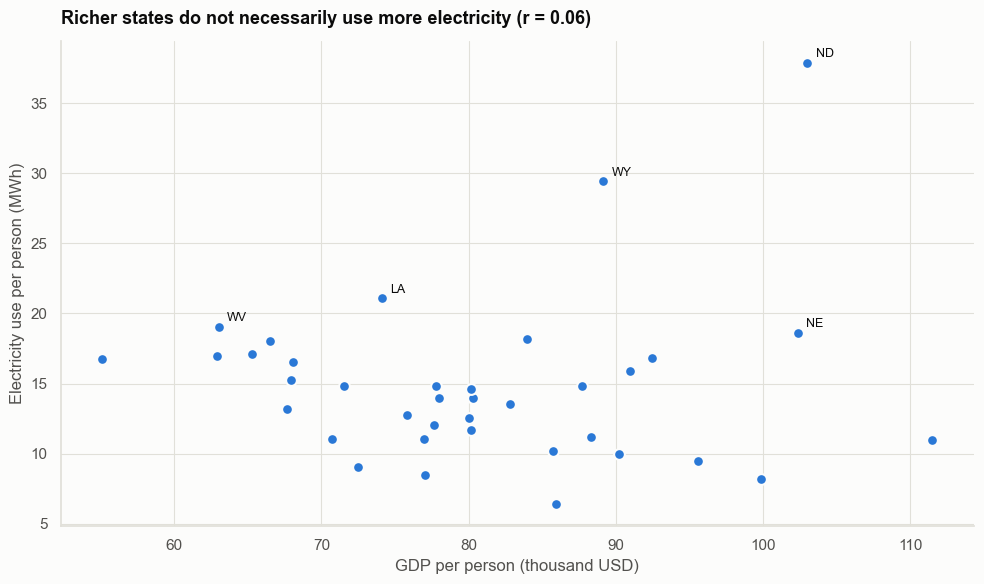

In [182]:
# All required fields already exist in the unified dataset.
d = cons[
    (cons["year"] == 2025) & (~cons["affected_break"])
][["state_code", "total_sales_twh", "population", "gdp_per_capita"]].copy()

d["kwh_per_person"] = d["total_sales_twh"] * 1e9 / d["population"]
r2 = d["gdp_per_capita"].corr(d["kwh_per_person"])

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(d["gdp_per_capita"] / 1e3, d["kwh_per_person"] / 1e3,
           s=60, color=BLUE, edgecolor=SURFACE, linewidth=1.5)
for _, row in d.nlargest(5, "kwh_per_person").iterrows():
    ax.annotate(row["state_code"],
                (row["gdp_per_capita"] / 1e3, row["kwh_per_person"] / 1e3),
                xytext=(6, 4), textcoords="offset points", color=INK, fontsize=9)
style(ax, f"Richer states do not necessarily use more electricity (r = {r2:.2f})",
      "GDP per person (thousand USD)", "Electricity use per person (MWh)")
plt.tight_layout(); plt.show()

**Comment:** this links the electricity part to the economy part, using only states without the reporting break and without DC. The correlation is a simple pairwise number: climate, industry mix and prices also drive electricity use, so do not read it as cause and effect.

## 7. Power-System Engineering Analysis

The previous sections describe *what* happened (mix, consumption, prices, GDP). This section adds the **engineering view**: it converts energy (TWh) into power (GW), estimates the installed capacity behind each source, measures how diversified the supply is, checks the emission factors, and explains *why* power-sector emissions changed using the Kaya identity.

**Scope and conventions**
- Only the **50 states** are used (DC has no population record) and the years **2001-2025** (generation data start in 2001).
- Generation and emissions come from the unified dataset (`cons`), so everything here stays consistent with Sections 4-6.
- Equations are given in the text before each calculation. Assumed engineering parameters (capacity factors) are collected in one dictionary so they can be changed and the notebook re-run.

### 7.1 Preparation: the 50-state engineering table

In [183]:
HOURS_PER_YEAR = 8760     # hours in a non-leap year (leap years are ignored: error < 0.3 %)
MIN_GEN_TWH = 20          # ignore very small systems when ranking states

GEN_COLS  = [c for c in cons.columns if c.startswith("generation_twh__")]
EMIS_COLS = [c for c in cons.columns if c.startswith("emissions_mtco2e__")]

def source_name(col):
    return col.split("__", 1)[1]

# DC has no population record, so the 50 states are used; generation data start in 2001
eng = cons[(cons["state_code"] != "DC") & (cons["year"] >= 2001)].copy()
eng["gen_total_twh"] = eng[GEN_COLS].sum(axis=1, min_count=1)
eng["emis_total_mt"] = eng[EMIS_COLS].sum(axis=1, min_count=1)

# National totals by year (sum of the 50 states)
eng_nat = eng.groupby("year").agg(
    gen_twh=("gen_total_twh", "sum"), emis_mt=("emis_total_mt", "sum"),
    pop=("population", "sum"), gdp_real_musd=("real_gdp_musd2017", "sum"))

# National generation and emissions by source
gen_src  = eng.groupby("year")[GEN_COLS].sum().rename(columns=source_name)
emis_src = eng.groupby("year")[EMIS_COLS].sum().rename(columns=source_name)

print(f"{eng['state_code'].nunique()} states, {eng['year'].min()}-{eng['year'].max()}")
print("Sources:", ", ".join(gen_src.columns))
display(eng_nat.iloc[[0, -1]].round(1))

50 states, 2001-2025
Sources: Bioenergy, Coal, Gas, Hydro, Nuclear, Other fossil, Other renewables, Solar, Wind


,gen_twh,emis_mt,pop,gdp_real_musd
year,,,,
2001,"3,726.90","2,272.80","284,394,451.00","14,088,819.90"
2025,"4,516.10","1,735.70","341,091,212.00","23,671,142.80"


### 7.2 From energy to power: average electric power and power per person

Annual energy $E$ (TWh) is the area under the load curve. Dividing by the period $T$ gives the **average power**:

$$P_{avg}\,[\mathrm{GW}] = \frac{E\,[\mathrm{TWh}]\times 1000}{T\,[\mathrm{h}]}, \qquad T = 8760\ \mathrm{h}$$

$$p_{pc}\,[\mathrm{W/person}] = \frac{P_{avg}\times 10^{9}}{N_{pop}}$$

Average power is the *continuous* output the whole fleet would need to supply the year's energy. The system must be built for the **peak**, which is higher; annual data cannot show the peak (see Section 9).

,Generation (TWh),Average power (GW),Population,Average power per person (W)
year,,,,
2001,"3,726.90",425.40,"284,394,451.00","1,496.00"
2010,"4,113.70",469.60,"308,721,861.00","1,521.10"
2025,"4,516.10",515.50,"341,091,212.00","1,511.40"


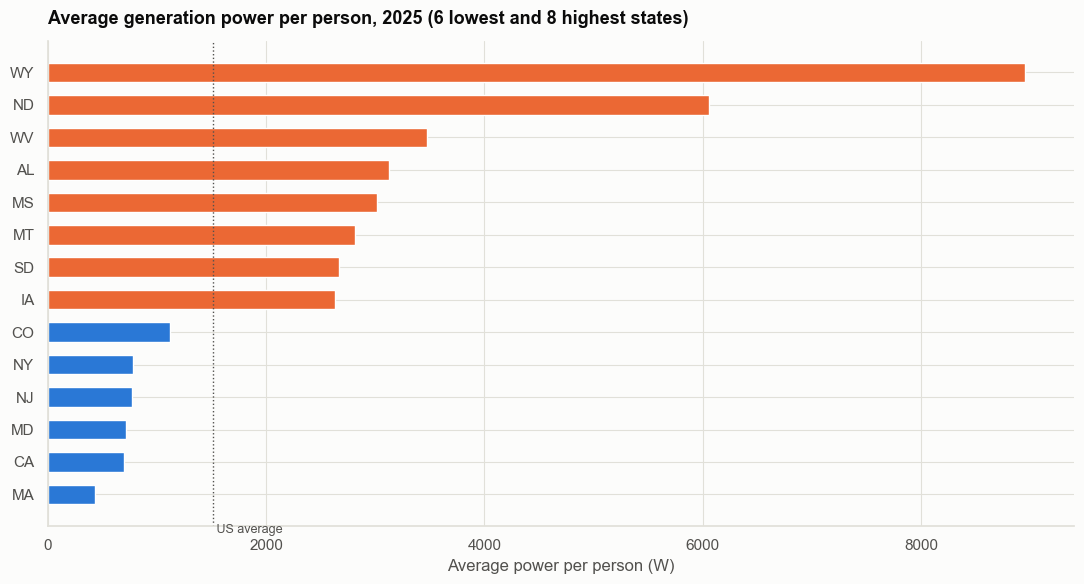

In [184]:
eng_nat["avg_power_gw"] = eng_nat["gen_twh"] * 1000 / HOURS_PER_YEAR          # P = E / T
eng_nat["watts_per_person"] = eng_nat["avg_power_gw"] * 1e9 / eng_nat["pop"]  # W per person

table = eng_nat.loc[[2001, 2010, 2025], ["gen_twh", "avg_power_gw", "pop", "watts_per_person"]]
table.columns = ["Generation (TWh)", "Average power (GW)", "Population", "Average power per person (W)"]
display(table.round(1))

# State ranking in 2025 (generation-based, so net exporters of electricity appear high)
e25 = eng[eng["year"] == 2025].set_index("state_code").copy()
e25["avg_power_gw"] = e25["gen_total_twh"] * 1000 / HOURS_PER_YEAR
e25["w_per_person"] = e25["avg_power_gw"] * 1e9 / e25["population"]
rank = e25[e25["gen_total_twh"] >= MIN_GEN_TWH]["w_per_person"].sort_values()
show = pd.concat([rank.head(6), rank.tail(8)])

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(show.index, show.values, color=[BLUE] * 6 + [ORANGE] * 8, height=0.6)
ax.axvline(eng_nat.loc[2025, "watts_per_person"], color=MUTED, lw=1, ls=":")
ax.text(eng_nat.loc[2025, "watts_per_person"], -0.9, " US average", color=MUTED, fontsize=9, va="top")
style(ax, "Average generation power per person, 2025 (6 lowest and 8 highest states)",
      "Average power per person (W)", "")
plt.tight_layout(); plt.show()

**Comment:** the national figure is a continuous output of roughly 1.5 kW per person (see the table). The very high states are mostly **net exporters** (they generate far more than their own population uses), so this ranking is about *generation*, not *consumption*. The consumption view is in Section 6.12.

### 7.3 Installed capacity implied by the energy data

The dataset gives energy, not capacity. The two are linked by the **capacity factor** (CF):

$$CF = \frac{E}{P_{rated}\cdot T} \quad\Longrightarrow\quad P_{rated}\,[\mathrm{GW}] = \frac{E\,[\mathrm{TWh}]\times 1000}{CF \times 8760}$$

Because wind and solar have low CF, a source can hold a much larger share of **capacity** than of **energy**. This is the reason a high renewable share needs more installed MW than the energy share suggests.

The capacity factors below are **assumed typical values for the US fleet** (nuclear runs almost flat out; gas, wind and solar are lower). They are estimates, kept in one dictionary so they can be replaced with measured values from the EIA-860/EIA-923 forms.

,CF,gen_2001_twh,cap_2001_gw,gen_2025_twh,cap_2025_gw,cap_change_gw
Nuclear,0.92,768.83,95.40,784.78,97.38,1.98
Coal,0.45,"1,903.95",482.99,737.15,187.00,-295.99
Gas,0.40,639.13,182.40,"1,806.41",515.53,333.13
Hydro,0.38,208.14,62.53,240.58,72.27,9.75
Wind,0.34,6.74,2.26,464.20,155.85,153.59
Solar,0.24,0.00,0.00,388.41,184.75,184.75


Implied capacity of these six sources: 826 GW (2001) -> 1213 GW (2025)


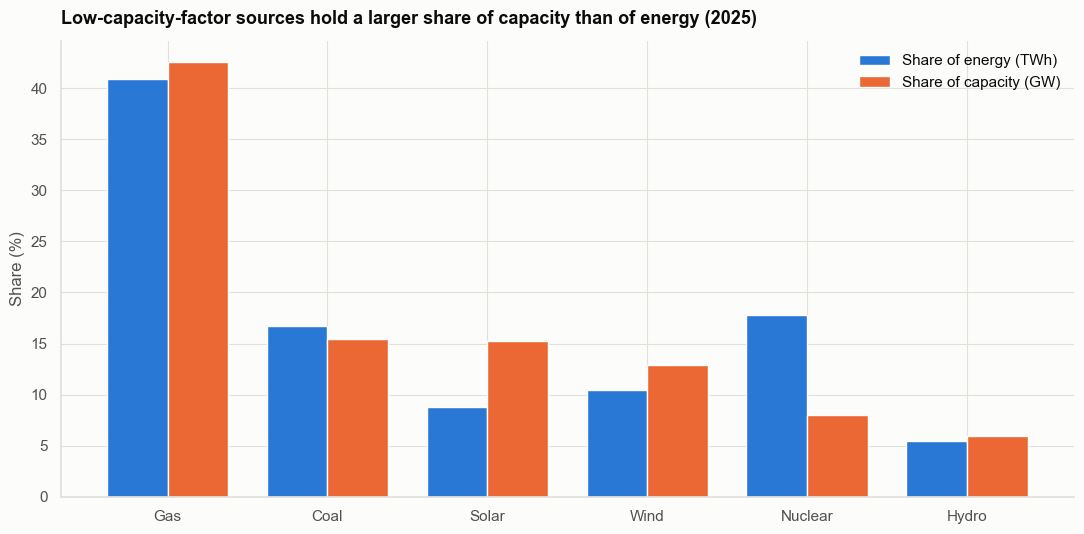

In [185]:
# Assumed capacity factors (editable). Typical US-fleet values; replace with measured data if available.
ASSUMED_CF = {"Nuclear": 0.92, "Coal": 0.45, "Gas": 0.40, "Hydro": 0.38, "Wind": 0.34, "Solar": 0.24}

cap = pd.DataFrame({"CF": pd.Series(ASSUMED_CF)})
for yr in (2001, 2025):
    cap[f"gen_{yr}_twh"] = gen_src.loc[yr, cap.index]
    cap[f"cap_{yr}_gw"] = cap[f"gen_{yr}_twh"] * 1000 / (cap["CF"] * HOURS_PER_YEAR)   # P_rated = E / (CF*T)
cap["cap_change_gw"] = cap["cap_2025_gw"] - cap["cap_2001_gw"]
display(cap.round(2))
print(f"Implied capacity of these six sources: {cap['cap_2001_gw'].sum():.0f} GW (2001) -> {cap['cap_2025_gw'].sum():.0f} GW (2025)")

# Share of energy vs share of capacity in 2025
cmp = pd.DataFrame({
    "Share of energy (%)":   cap["gen_2025_twh"] / cap["gen_2025_twh"].sum() * 100,
    "Share of capacity (%)": cap["cap_2025_gw"] / cap["cap_2025_gw"].sum() * 100,
}).sort_values("Share of capacity (%)", ascending=False)

fig, ax = plt.subplots()
x = np.arange(len(cmp)); w = 0.38
ax.bar(x - w / 2, cmp["Share of energy (%)"], w, color=BLUE, label="Share of energy (TWh)")
ax.bar(x + w / 2, cmp["Share of capacity (%)"], w, color=ORANGE, label="Share of capacity (GW)")
ax.set_xticks(x); ax.set_xticklabels(cmp.index)
ax.legend()
style(ax, "Low-capacity-factor sources hold a larger share of capacity than of energy (2025)", "", "Share (%)")
plt.tight_layout(); plt.show()

**Comment:** with these assumptions nuclear supplies a clearly larger share of the *energy* than of the *capacity*, gas is roughly balanced, and wind and especially solar show the opposite (solar's share of capacity is close to twice its share of energy). The implied capacity totals depend directly on the assumed CF (they scale as $1/CF$), so treat them as estimates, not measurements. Capacity alone also overstates the firm contribution of wind and solar at peak time, which is why planners use a *capacity credit* below 100% for them.

### 7.4 Diversity of the generation mix (HHI and Shannon entropy)

Supply diversity is an energy-security indicator: a mix dominated by one fuel is exposed to its price, outage or policy risk. With $s_i$ the share of source $i$:

$$HHI = \sum_i (100\,s_i)^2 \quad (0\text{-}10\,000), \qquad H = -\sum_i s_i \ln s_i, \qquad N_{eff} = e^{H}$$

A **lower HHI** and a **higher $N_{eff}$** (the "effective number of equally sized sources") mean a more diversified mix.

,HHI,Shannon_H,N_effective
year,,,
2001,"3,375.88",1.34,3.83
2010,"3,024.75",1.42,4.12
2025,"2,377.97",1.67,5.31


Most diversified states (lowest HHI):


,HHI,Shannon_H,N_effective
state_code,,,
MN,"2,093.00",1.70,5.30
CO,"2,526.80",1.50,4.30
CA,"2,580.80",1.60,4.80
AR,"2,608.60",1.50,4.40
NM,"2,694.80",1.40,3.90


Least diversified states (highest HHI):


,HHI,Shannon_H,N_effective
state_code,,,
KY,"5,036.20",0.90,2.50
FL,"5,412.60",1.00,2.60
LA,"5,469.30",1.00,2.70
MS,"5,722.30",0.90,2.40
WV,"7,593.40",0.60,1.70


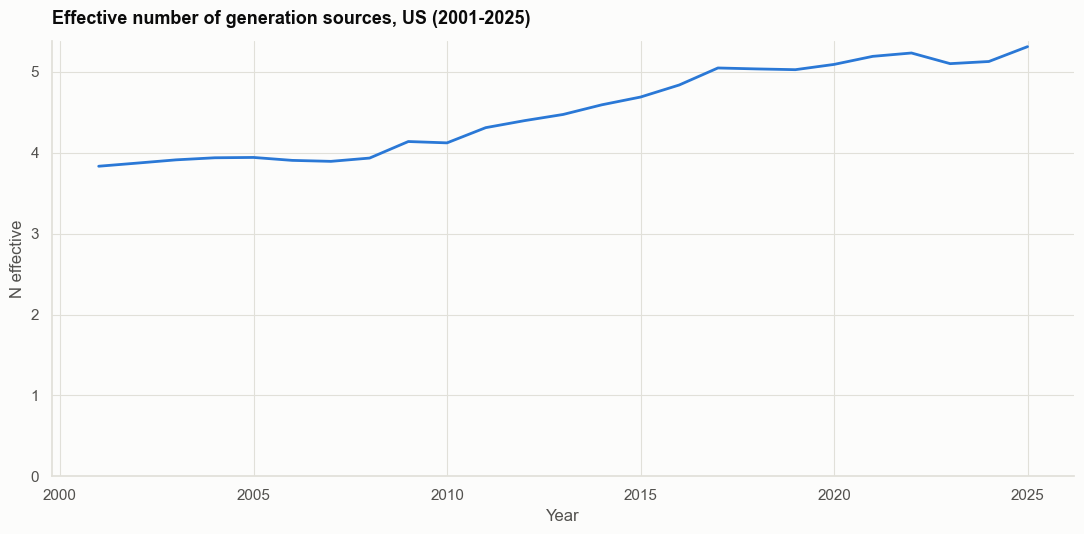

In [186]:
mix_frac = gen_src.div(gen_src.sum(axis=1), axis=0)            # s_i, shares as fractions

def diversity(frac):
    pos = frac.where(frac > 0)                                  # avoid log(0)
    hhi = (frac ** 2).sum(axis=1) * 10_000
    entropy = -(pos * np.log(pos)).sum(axis=1)
    return pd.DataFrame({"HHI": hhi, "Shannon_H": entropy, "N_effective": np.exp(entropy)})

div_nat = diversity(mix_frac)
display(div_nat.loc[[2001, 2010, 2025]].round(2))

# State level, 2025 (states generating at least MIN_GEN_TWH)
s25 = eng[eng["year"] == 2025].set_index("state_code")[GEN_COLS].fillna(0).rename(columns=source_name)
s25 = s25[s25.sum(axis=1) >= MIN_GEN_TWH]
div_state = diversity(s25.div(s25.sum(axis=1), axis=0)).sort_values("HHI")
print("Most diversified states (lowest HHI):")
display(div_state.head(5).round(1))
print("Least diversified states (highest HHI):")
display(div_state.tail(5).round(1))

fig, ax = plt.subplots()
ax.plot(div_nat.index, div_nat["N_effective"], color=BLUE, lw=2)
ax.set_ylim(0, None)
style(ax, "Effective number of generation sources, US (2001-2025)", "Year", "N effective")
plt.tight_layout(); plt.show()

**Comment:** in 2001 coal supplied about half of US energy, so the mix was concentrated. As coal gave way to gas, wind and solar, the national mix became **more diversified** (lower HHI). Diversity at national level can hide concentration at state level: the second table shows states that still depend on one source.

### 7.5 Emission factors and the effect of the changing mix

The emission factor of source $i$ is its emissions divided by its energy, and the grid intensity is the share-weighted average:

$$EF_i = \frac{E^{CO_2e}_i\,[\mathrm{Mt}]}{G_i\,[\mathrm{TWh}]}\times 1000 \;\; [\mathrm{g\,CO_2e/kWh}], \qquad I = \sum_i s_i\,EF_i$$

Holding the 2025 emission factors fixed and swapping the 2001 mix for the 2025 mix isolates the **mix effect** (the part of the fall in intensity that comes only from changing *what* is generated):

$$\Delta E_{mix} = \big(I_{2001\text{ mix}} - I_{2025}\big)\times G_{2025}\,/\,1000 \;\; [\mathrm{Mt\,CO_2e}]$$

In [187]:
# Lifecycle reference values: IPCC AR5 WG3, Annex III (2014), median, g CO2e/kWh
LIFECYCLE_G_PER_KWH = {"Coal": 820, "Gas": 490, "Bioenergy": 230, "Solar": 48, "Hydro": 24, "Nuclear": 12, "Wind": 11}

ef = pd.DataFrame({"generation_twh": gen_src.loc[2025], "emissions_mt": emis_src.loc[2025]})
ef = ef[ef["generation_twh"] > 0]
ef["EF_dataset_g_kwh"] = ef["emissions_mt"] / ef["generation_twh"] * 1000
ef["EF_IPCC_lifecycle"] = pd.Series(LIFECYCLE_G_PER_KWH)
ef["difference"] = ef["EF_dataset_g_kwh"] - ef["EF_IPCC_lifecycle"]
display(ef.sort_values("EF_dataset_g_kwh", ascending=False).round(1))

# Mix effect: 2025 emission factors applied to the 2001 and 2025 mixes
EF25 = (emis_src.loc[2025] / gen_src.loc[2025].where(gen_src.loc[2025] > 0) * 1000).fillna(0)
mix01 = gen_src.loc[2001] / gen_src.loc[2001].sum()
mix25 = gen_src.loc[2025] / gen_src.loc[2025].sum()
I_2025 = (mix25 * EF25).sum()                      # equals total emissions / total generation
I_2001_mix = (mix01 * EF25).sum()                  # what 2025 would be with the 2001 mix
G25 = gen_src.loc[2025].sum()
avoided_mt = (I_2001_mix - I_2025) * G25 / 1000
check = eng_nat.loc[2025, "emis_mt"] / eng_nat.loc[2025, "gen_twh"] * 1000

print(f"Grid intensity 2025 (actual mix)        : {I_2025:6.1f} g/kWh   (check from totals: {check:.1f})")
print(f"Grid intensity 2025 with the 2001 mix   : {I_2001_mix:6.1f} g/kWh")
print(f"Emissions avoided by the mix change     : {avoided_mt:6.0f} Mt CO2e in 2025 "
      f"({avoided_mt / (I_2001_mix * G25 / 1000) * 100:.0f} % of the 2001-mix level)")

,generation_twh,emissions_mt,EF_dataset_g_kwh,EF_IPCC_lifecycle,difference
Coal,737.20,700.20,949.80,820.00,129.80
Other fossil,31.00,21.70,700.00,NaN,NaN
Gas,"1,806.40",970.60,537.30,490.00,47.30
Bioenergy,46.00,10.60,229.90,230.00,-0.10
Solar,388.40,18.60,48.00,48.00,-0.00
Hydro,240.60,5.80,24.00,24.00,-0.00
Wind,464.20,4.00,8.50,11.00,-2.50
Nuclear,784.80,4.20,5.40,12.00,-6.60
Other renewables,17.60,0.10,4.10,NaN,NaN


Grid intensity 2025 (actual mix)        :  384.3 g/kWh   (check from totals: 384.3)
Grid intensity 2025 with the 2001 mix   :  608.4 g/kWh
Emissions avoided by the mix change     :   1012 Mt CO2e in 2025 (37 % of the 2001-mix level)


**Comment:** the dataset factors can be compared with the IPCC lifecycle medians in the same table. Coal has by far the highest factor and wind, nuclear and hydro the lowest, so the intensity of the grid is controlled almost entirely by the *mix*. If the dataset factors are the same every year, then the whole fall in intensity is a mix effect, and the "avoided emissions" line above measures it in Mt.

### 7.6 Why did power-sector emissions change? Kaya identity and LMDI decomposition

The **Kaya identity** writes emissions as a product of four factors:

$$C = N \times \frac{Y}{N} \times \frac{G}{Y} \times \frac{C}{G}$$

where $N$ is population, $Y/N$ real GDP per person (affluence), $G/Y$ the electricity generated per unit of GDP (electricity intensity of the economy) and $C/G$ the carbon intensity of generation.

To split the change $\Delta C = C_T - C_0$ between the factors, the **additive LMDI-I** method (Ang, 2005) is used:

$$\Delta C_x = L(C_T, C_0)\,\ln\frac{x_T}{x_0}, \qquad L(a,b) = \frac{a-b}{\ln a - \ln b}$$

The four effects add up *exactly* to $\Delta C$ (no residual), which is why LMDI is preferred over simpler ratios. Real GDP is the sum of the 50 states' chained-2017-dollar GDP (an approximation, because chained dollars are not strictly additive).

,Population,GDP per person,Electricity per GDP,CO2e per kWh,Total change
2001-2007,132.00,257.00,-138.00,-45.00,206.00
2007-2025,263.00,477.00,-560.00,-923.00,-743.00
2001-2025,362.00,672.00,-651.00,-920.00,-537.00


Effects in Mt CO2e. A positive value pushed emissions up, a negative value pushed them down.


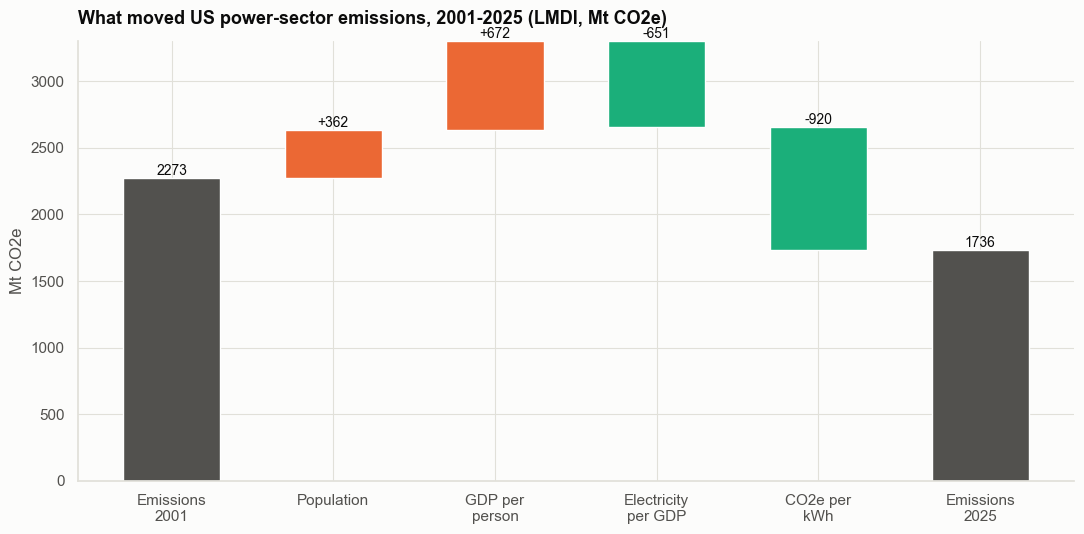

In [188]:
kaya = eng_nat[["pop", "gdp_real_musd", "gen_twh", "emis_mt"]].copy()
kaya["affluence"]        = kaya["gdp_real_musd"] * 1e6 / kaya["pop"]            # real USD per person
kaya["elec_intensity"]   = kaya["gen_twh"] * 1e9 / (kaya["gdp_real_musd"] * 1e6)  # kWh per USD
kaya["carbon_intensity"] = kaya["emis_mt"] * 1e12 / (kaya["gen_twh"] * 1e9)       # g CO2e per kWh

FACTORS = {"Population": "pop", "GDP per person": "affluence",
           "Electricity per GDP": "elec_intensity", "CO2e per kWh": "carbon_intensity"}

def log_mean(a, b):
    return a if np.isclose(a, b) else (a - b) / np.log(a / b)

def lmdi(df, y0, y1):
    c0, c1 = df.loc[y0, "emis_mt"], df.loc[y1, "emis_mt"]
    L = log_mean(c1, c0)
    effects = {label: L * np.log(df.loc[y1, col] / df.loc[y0, col]) for label, col in FACTORS.items()}
    return effects, c0, c1

periods = [(2001, 2007), (2007, 2025), (2001, 2025)]
rows = {}
for y0, y1 in periods:
    eff, c0, c1 = lmdi(kaya, y0, y1)
    assert np.isclose(sum(eff.values()), c1 - c0), "LMDI effects must add up to the total change"
    rows[f"{y0}-{y1}"] = {**eff, "Total change": c1 - c0}

display(pd.DataFrame(rows).T.round(0))
print("Effects in Mt CO2e. A positive value pushed emissions up, a negative value pushed them down.")

# Waterfall for the full period
eff, c0, c1 = lmdi(kaya, 2001, 2025)
labels = ["Emissions\n2001", "Population", "GDP per\nperson", "Electricity\nper GDP", "CO2e per\nkWh", "Emissions\n2025"]

fig, ax = plt.subplots()
running = c0
ax.bar(0, c0, color=MUTED, width=0.6)
for i, (name, v) in enumerate(eff.items(), start=1):
    ax.bar(i, v, bottom=running, color=ORANGE if v > 0 else AQUA, width=0.6)
    ax.text(i, max(running, running + v) + 0.01 * c0, f"{v:+.0f}", ha="center", fontsize=10)
    running += v
ax.bar(5, c1, color=MUTED, width=0.6)
ax.text(0, c0 + 0.01 * c0, f"{c0:.0f}", ha="center", fontsize=10)
ax.text(5, c1 + 0.01 * c0, f"{c1:.0f}", ha="center", fontsize=10)
ax.set_xticks(range(6)); ax.set_xticklabels(labels)
style(ax, "What moved US power-sector emissions, 2001-2025 (LMDI, Mt CO2e)", "", "Mt CO2e")
plt.tight_layout(); plt.show()

**Comment:** growth in population and in GDP per person pushes emissions **up**; the economy needing less electricity per dollar of GDP and, above all, a cleaner kWh push them **down**. Compare the two sub-periods: the table shows when the carbon-intensity effect became large enough to outweigh the growth effects. This is the quantitative link between Section 5 (economy and population) and Sections 4 and 6 (mix and emissions).

### 7.7 Decoupling: economy, electricity and emissions (index 2001 = 100)

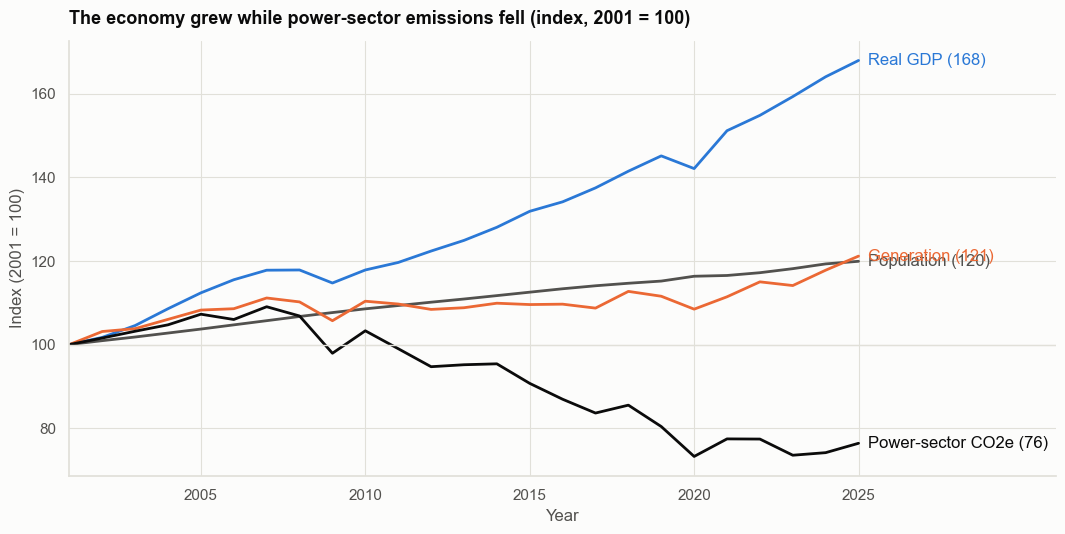

In [189]:
idx = eng_nat[["gdp_real_musd", "pop", "gen_twh", "emis_mt"]].div(eng_nat.iloc[0]) * 100
series = [("gdp_real_musd", "Real GDP", BLUE), ("pop", "Population", MUTED),
          ("gen_twh", "Generation", ORANGE), ("emis_mt", "Power-sector CO2e", INK)]

fig, ax = plt.subplots()
for col, label, colour in series:
    ax.plot(idx.index, idx[col], color=colour, lw=2)
    ax.text(idx.index.max() + 0.3, idx[col].iloc[-1], f"{label} ({idx[col].iloc[-1]:.0f})",
            color=colour, va="center")
ax.axhline(100, color=GRID, lw=1)
ax.set_xlim(idx.index.min(), idx.index.max() + 6)
ax.set_xticks(range(2005, 2026, 5))
style(ax, "The economy grew while power-sector emissions fell (index, 2001 = 100)", "Year", "Index (2001 = 100)")
plt.tight_layout(); plt.show()

**Comment:** when GDP rises while emissions fall, the two are **decoupled**. Generation grew slower than GDP (the economy became less electricity-intensive), and emissions fell even faster than generation (the grid became cleaner). The Kaya decomposition above gives the size of each of these effects.

### 7.8 System-level energy balance: retail sales versus generation

For the 37 states without the reporting break, the ratio of retail sales $S$ to generation $G$ is a simple indicator of how much generated energy reaches paying customers:

$$\eta_{sys} = \frac{S}{G}\times 100, \qquad \text{gap} = 100 - \eta_{sys}$$

The gap is **not** only transmission and distribution (T&D) losses. It also contains power-plant auxiliary use, customer self-generation and direct use that is not sold through the grid, and the **net flow between states**: a net exporter has $\eta_{sys}<100\%$ and a net importer can even exceed 100%.

37 states without the break | mean eta = 87.9 % | range 85.9-89.7 %
Lowest sales/generation (net exporters): {'WY': 37.0, 'MT': 45.0, 'AL': 62.0, 'WV': 63.0, 'MS': 63.0}
Highest sales/generation (net importers): {'MN': 106.0, 'MO': 110.0, 'ID': 127.0, 'VA': 132.0, 'TN': 143.0}


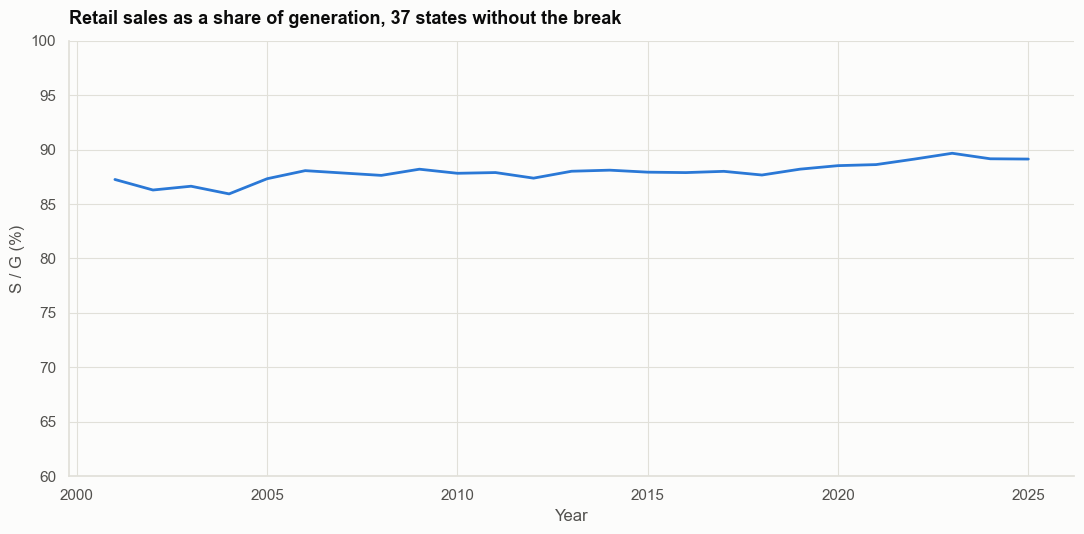

In [190]:
clean_st = eng[~eng["affected_break"]]
eta = clean_st.groupby("year").agg(sales=("total_sales_twh", "sum"), gen=("gen_total_twh", "sum"))
eta["eta_pct"] = eta["sales"] / eta["gen"] * 100
eta["gap_pct"] = 100 - eta["eta_pct"]
print(f"{clean_st['state_code'].nunique()} states without the break | "
      f"mean eta = {eta['eta_pct'].mean():.1f} % | range {eta['eta_pct'].min():.1f}-{eta['eta_pct'].max():.1f} %")

# State ratio in 2025: net exporters (low) and net importers (high)
s25r = clean_st[clean_st["year"] == 2025].set_index("state_code")
s25r = s25r[s25r["gen_total_twh"] >= MIN_GEN_TWH]
ratio25 = (s25r["total_sales_twh"] / s25r["gen_total_twh"] * 100).sort_values()
print("Lowest sales/generation (net exporters):", ratio25.head(5).round(0).to_dict())
print("Highest sales/generation (net importers):", ratio25.tail(5).round(0).to_dict())

fig, ax = plt.subplots()
ax.plot(eta.index, eta["eta_pct"], color=BLUE, lw=2)
ax.set_ylim(60, 100)
style(ax, "Retail sales as a share of generation, 37 states without the break", "Year", "S / G (%)")
plt.tight_layout(); plt.show()

**Comment:** the ratio is stable over time, so the gap behaves like a structural property of the system and not like a trend. A gap of about 12% is larger than typical T&D losses (EIA estimates around 5%), which confirms that auxiliary use, non-retail energy and interstate trade make up the rest. States far from 100% in either direction are the ones where the state-level generation and consumption figures should not be compared directly.

### 7.9 Electricity intensity of the economy by state (2025)

How much electricity a state needs to produce one dollar of output depends mainly on its **industrial structure**:

$$\varepsilon_{GDP} = \frac{S\,[\mathrm{kWh}]}{Y_{real}\,[\mathrm{USD}]}$$

The 37 states without the reporting break are used because the 14 affected states under-report $S$.

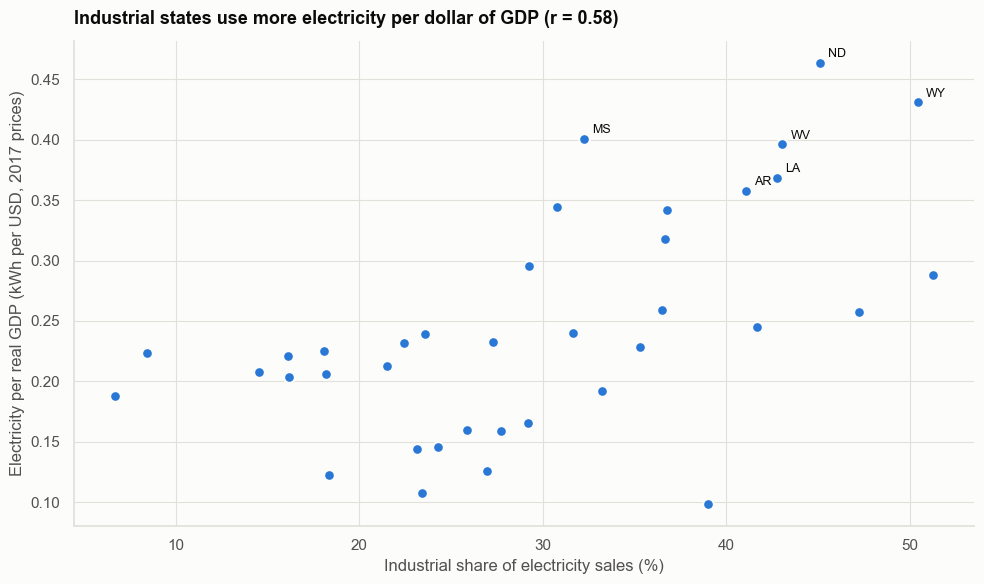

Lowest electricity intensity : {'HI': 0.098, 'AK': 0.107, 'WA': 0.123, 'CO': 0.126, 'VT': 0.144}
Highest electricity intensity: {'ND': 0.464, 'WY': 0.431, 'MS': 0.401, 'WV': 0.397, 'LA': 0.369}


In [191]:
c25 = eng[(eng["year"] == 2025) & (~eng["affected_break"])].set_index("state_code").copy()
c25["kwh_per_usd"] = c25["total_sales_twh"] * 1e9 / (c25["real_gdp_musd2017"] * 1e6)
c25["industrial_share_pct"] = c25["ind_sales_twh"] / c25["total_sales_twh"] * 100
r_ind = c25["industrial_share_pct"].corr(c25["kwh_per_usd"])

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(c25["industrial_share_pct"], c25["kwh_per_usd"], s=60, color=BLUE, edgecolor=SURFACE, linewidth=1.5)
for code_, row in c25.nlargest(6, "kwh_per_usd").iterrows():
    ax.annotate(code_, (row["industrial_share_pct"], row["kwh_per_usd"]),
                xytext=(6, 4), textcoords="offset points", color=INK, fontsize=9)
style(ax, f"Industrial states use more electricity per dollar of GDP (r = {r_ind:.2f})",
      "Industrial share of electricity sales (%)", "Electricity per real GDP (kWh per USD, 2017 prices)")
plt.tight_layout(); plt.show()

print("Lowest electricity intensity :", c25["kwh_per_usd"].nsmallest(5).round(3).to_dict())
print("Highest electricity intensity:", c25["kwh_per_usd"].nlargest(5).round(3).to_dict())

**Comment:** this is a correlation across states, not a causal estimate. Climate (cooling and heating), electricity price and the presence of energy-intensive industry (metals, chemicals, data centres) all move the intensity; weather normalisation is listed as future work in Section 9.

### 7.10 Summary of the engineering results

In [192]:
y0, y1 = 2001, 2025
eff, c0, c1 = lmdi(kaya, y0, y1)
main = max(eff, key=lambda k: abs(eff[k]))

print("ENGINEERING SUMMARY (50 states)")
print(f"- Average generation power : {eng_nat.loc[y0, 'avg_power_gw']:.0f} GW -> {eng_nat.loc[y1, 'avg_power_gw']:.0f} GW "
      f"({eng_nat.loc[y1, 'watts_per_person']:.0f} W per person in {y1}).")
print(f"- Implied capacity of the six main sources : {cap['cap_2001_gw'].sum():.0f} GW -> {cap['cap_2025_gw'].sum():.0f} GW "
      f"(assumed capacity factors).")
print(f"- Mix diversity : effective number of sources {div_nat.loc[y0, 'N_effective']:.2f} -> {div_nat.loc[y1, 'N_effective']:.2f}; "
      f"HHI {div_nat.loc[y0, 'HHI']:.0f} -> {div_nat.loc[y1, 'HHI']:.0f}.")
print(f"- Grid carbon intensity : {kaya.loc[y0, 'carbon_intensity']:.0f} -> {kaya.loc[y1, 'carbon_intensity']:.0f} g CO2e/kWh; "
      f"the mix change alone avoided about {avoided_mt:.0f} Mt CO2e in {y1}.")
print(f"- Power-sector emissions : {c0:.0f} -> {c1:.0f} Mt CO2e ({(c1 / c0 - 1) * 100:+.0f} %). "
      f"Largest single effect (LMDI): {main} ({eff[main]:+.0f} Mt).")
print(f"- Sales / generation in the 37 clean states : {eta['eta_pct'].mean():.1f} % on average.")

ENGINEERING SUMMARY (50 states)
- Average generation power : 425 GW -> 516 GW (1511 W per person in 2025).
- Implied capacity of the six main sources : 826 GW -> 1213 GW (assumed capacity factors).
- Mix diversity : effective number of sources 3.83 -> 5.31; HHI 3376 -> 2378.
- Grid carbon intensity : 610 -> 384 g CO2e/kWh; the mix change alone avoided about 1012 Mt CO2e in 2025.
- Power-sector emissions : 2273 -> 1736 Mt CO2e (-24 %). Largest single effect (LMDI): CO2e per kWh (-920 Mt).
- Sales / generation in the 37 clean states : 87.9 % on average.


## 8. Key Insights and Conclusions

**1. The US electricity generation mix changed substantially.**
- Coal fell from 51.1% (2001) to 16.3% (2025). Gas rose from 17.1% to 40.0%. Wind went from 0.2% to 10.3% and solar from about 0% to 8.6%. Nuclear slipped from 20.6% to 17.4%.
- Total generation grew about 21% over the period, from 3,727 to 4,517 TWh.

**2. Coal was replaced by different things in different places.**
- In industrial states gas took over: Ohio lost 62.9 points of coal share and gained 54.3 of gas; Pennsylvania lost 49.9 and gained 56.4.
- In the plains and the south-west wind and solar took over: Iowa is at 61.0% wind + solar and New Mexico at 53.1%, with gas up only 10-12 points.

**3. Consumption was flat, but prices were not.**
- National consumption was 3,421 TWh in 2000 and 3,480 TWh in 2025 (+1.7%).
- The sales-weighted average price rose from 6.81 to 12.98 cents/kWh (+90%). Residential rose 101%, industrial 73%, commercial 66%.
- Prices are **nominal**. General inflation over 2000-2025 was of a similar size, so the real increase is much smaller. Deflate the prices before claiming that electricity became more expensive in real terms.
- Prices differ a lot between states: Hawaii (35.6), Rhode Island (28.2) and Connecticut (26.7) are the most expensive, North Dakota (8.2) and Nebraska (9.4) the cheapest.

**4. A data break, not a demand drop, explains the national gap.**
- Reported consumption fell sharply in 14 states from about 2010 (Maine went from 11.3 TWh in 2009 to 0.15 TWh in 2010). Their consumption/generation ratio fell from about 99% to 52-67%, while the other 37 states stayed near 88%.
- These 14 states account for 579.6 TWh of the 630 TWh gap between expected and reported national consumption (92%). Their share of national consumption "dropped" from 30.6% to 15.0%.
- Excluding them, consumption in the 37 clean states grew 26.6% from 2000 to 2025 (about 0.95% per year). Any national trend that includes the 14 states is misleading.

**5. A few states carry most of the system.**
- The 10 largest generating states produce 50.1% of US electricity, and the 10 largest consumers use 51.2%.
- Texas is the largest consumer (533 TWh in 2025, 188 TWh of it industrial) and the largest generator (596 TWh). Among the clean states it also had the largest absolute growth (+215 TWh since 2000). North Dakota had the highest relative growth (+221.6%).

**6. Economic size follows population, but GDP per capita tells a different story.**
- California, Texas, New York, Florida and Illinois have the largest GDP in 2025, and mostly the same states are at the top for population. GDP correlates strongly with population (r = 0.93 over all years) but only weakly with GDP per capita (0.37), and population is almost unrelated to GDP per capita (0.15).
- The per-capita ranking is different: New York, Delaware, Massachusetts, Washington and California lead. Delaware is among the 10 smallest economies but second in GDP per capita.

**7. Demand mix and growth.**
- In the 37 clean states residential is 37.6% of demand, commercial 35.0% and industrial 27.4% (2025).
- Growth is concentrated: North Dakota +222%, Texas and New Mexico +68%, while Montana, Michigan and Washington shrank.


**8. Engineering view (Section 7).**
- Converting energy to power shows the system as a continuous output of hundreds of GW, and the implied capacity of wind and solar is much larger than their energy share because of their low capacity factors.
- The generation mix became more diversified (lower HHI, more effective sources) as coal lost its dominant position.
- The Kaya/LMDI decomposition shows that population and GDP growth pushed power-sector emissions up, while lower electricity use per dollar of GDP and, above all, a lower carbon intensity of each kWh pushed them down. The cleaner mix is the dominant reason for the fall in emissions.
- The sales-to-generation ratio of the 37 clean states is stable, so the gap between generation and sales is structural (auxiliary use, non-retail energy, T&D losses and interstate trade) and not a trend.

*The numbers behind these statements are printed in Section 7.10 when the notebook is run.*


## 9. Limitations and Recommended Extensions

### 9.1 Limitations of the present analysis

- **Nominal prices.** Prices in Sections 4 and 6 are not adjusted for inflation. Deflate them with the CPI or the GDP deflator before claiming a real increase.
- **Annual resolution.** Annual energy cannot show the **peak demand**, seasonal patterns, or the hourly effects of wind and solar (the "duck curve", curtailment).
- **Capacity is estimated, not measured.** Section 7.3 uses assumed capacity factors.
- **Reporting break.** The cause of the 2010 drop in 14 states is inferred from the data, not confirmed (see 9.2).
- **Correlations are not causes.** Climate, prices and industrial structure all affect electricity use.
- **Real GDP is a sum of chained-dollar state values**, which is only approximately additive.

### 9.2 Likely cause of the reporting break (to be verified)

The 14 affected states (CA, CT, DC, DE, IL, MA, MD, ME, NH, NJ, NY, OH, PA, RI) are essentially the states with **retail electric choice**, where customers can buy energy from a competitive supplier while the local utility only delivers it. EIA distinguishes *full-service (bundled)*, *energy-only* and *delivery-only* sales. If the consumption file counts only full-service sales after 2009, customers who moved to independent suppliers disappear from the series, even though they still consume the electricity.

Supporting evidence: (a) generation in these states did not fall; (b) the official EIA 2025 US retail total is about 4,080 TWh, roughly 600 TWh above the 3,480 TWh sum of states in this file, close to the 580 TWh "lost" in the 14 states; (c) Texas matches EIA's published 2025 value (533 TWh), so the file appears to follow EIA data.

This explanation is **probable but not confirmed**. It can be checked by comparing the full-service series with the total-industry series in EIA's "retail sales by state by provider" table for Maine and Ohio around 2009–2010.

### 9.3 Data and analyses that would strengthen the study

| Addition | Why it matters (domain view) | Typical data |
|---|---|---|
| **Installed capacity** by source and state | Replaces the assumed capacity factors by measured ones: $CF = E/(P_{rated}T)$ | EIA-860 (capacity), EIA-923 (generation, fuel) |
| **Hourly or peak demand** | Allows the **load factor** $LF = \dfrac{E}{P_{peak}\cdot T}$ and the **reserve margin** $RM = \dfrac{P_{installed}-P_{peak}}{P_{peak}}$ | EIA-930 |
| **Transmission and distribution losses** | Splits the 12% sales-to-generation gap into losses, own use and trade | EIA state electricity profiles |
| **Weather normalisation** | Removes climate from state consumption using heating and cooling degree-days: $E = a + b\,\mathrm{HDD} + c\,\mathrm{CDD}$ | NOAA |
| **Real prices** | Shows whether electricity became more expensive in real terms | CPI-U |
| **Generation cost** (LCOE) | Explains *why* gas, wind and solar replaced coal: $LCOE = \dfrac{\sum (I_t+O\&M_t+F_t)/(1+r)^t}{\sum E_t/(1+r)^t}$ | Lazard, NREL ATB |
| **Storage and flexibility** | A mix with a high share of variable renewables needs storage, ramping gas or interconnection | EIA-860 (storage) |
| **New demand drivers** | EVs, heat pumps and data centres are expected to end the flat-demand period | State load forecasts |